<a href="https://colab.research.google.com/github/HimadreeChy/Liver-Fibrosis-Classification/blob/main/Liver_Fibrosis_The_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =========================
# 0. CONFIGURATION
# =========================
import os, sys, subprocess, json, time, zipfile, shutil, glob
from pathlib import Path

PROJECT_ROOT = Path("/content/liver_fibrosis_project")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

# Install the packages needed by the pipeline.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "grad-cam", "captum", "openpyxl"], check=True)

# Copy the bundled project utility module into the Colab workspace.
# The project ZIP contains this file; if you are running the notebook standalone,
# upload/extract the project ZIP first.
print("Python:", sys.version)
print("GPU available:", __import__("torch").cuda.is_available())


Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
GPU available: False


## 1. Upload the dataset





In [ ]:
from google.colab import files
uploaded = files.upload()

zip_candidates = [Path("/content")/n for n in uploaded if n.lower().endswith(".zip")]
if not zip_candidates:
    raise FileNotFoundError("Please upload a .zip dataset containing F0/F1/F2/F3/F4 folders.")

DATA_ZIP = zip_candidates[0]
EXTRACT_DIR = Path("/content/dataset_extracted")
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DATA_ZIP, "r") as z:
    z.extractall(EXTRACT_DIR)

# Locate the actual class-root directory.
sys.path.insert(0, str(Path("/content/liver_fibrosis_project")))
# If the utility module is not there yet, the next setup cell can copy it.
print("Extracted:", DATA_ZIP, "->", EXTRACT_DIR)


KeyboardInterrupt: 

In [ ]:
# Locate project_utils.py. If absent, upload the project ZIP and extract it.
utility_files = list(Path("/content").rglob("project_utils.py"))
if not utility_files:
    print("project_utils.py not found. Please upload the generated project ZIP now.")
    up2 = files.upload()
    for n in up2:
        if n.endswith(".zip"):
            with zipfile.ZipFile(Path("/content")/n) as z:
                z.extractall("/content/liver_fibrosis_project")
    utility_files = list(Path("/content").rglob("project_utils.py"))

if not utility_files:
    raise FileNotFoundError("project_utils.py is required.")
utility_path = utility_files[0]
sys.path.insert(0, str(utility_path.parent))
from project_utils import *
print("Using:", utility_path)


In [ ]:
import torch

# =========================
# MASTER CONFIG
# =========================
CFG = {
    "seed": 42,
    "img_size": 224,
    "batch_size": 32,        # Reduce to 16/8 if GPU memory is insufficient.
    "workers": 2,
    "pretrained": True,
    "lr": 1e-4,
    "epochs": 8,              # Increase to 15–30 for final thesis training if time allows.
    "patience": 3,
    "imbalance_epochs": 3,    # Short screening run; retrain final models using selected strategy.
    "run_imbalance": True,
    "run_all_models": True,
    "run_full_ablation": True,  # Set True for full E1–E6 training; expensive.
    "save_checkpoints": True,
}
seed_everything(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)


DEVICE: cuda


## 2. Dataset analysis




In [ ]:
DATASET_ROOT = find_dataset_root(EXTRACT_DIR)
df = build_dataframe(DATASET_ROOT)
summary, duplicate_stems, corrupt, size_counts = inspect_dataset(df)

print("Dataset root:", DATASET_ROOT)
print("Total images:", len(df))
display(summary)
print("\nDuplicate stems appearing in multiple rows:", duplicate_stems["stem"].nunique())
print("Corrupt/unreadable images:", len(corrupt))
print("Most common image sizes:", size_counts.most_common(10))
if corrupt:
    print("First corrupt files:")
    display(pd.DataFrame(corrupt[:20], columns=["path","error"]))

if not duplicate_stems.empty:
    cross_label = duplicate_stems.groupby("stem")["label"].nunique()
    print("Repeated stems with conflicting labels:", int((cross_label > 1).sum()))


Dataset root: /content/dataset_extracted/Dataset/Dataset
Total images: 6323


,count,percentage
label,,
F0,2114,33.433497
F1,861,13.616954
F2,793,12.541515
F3,857,13.553693
F4,1698,26.854341



Duplicate stems appearing in multiple rows: 12
Corrupt/unreadable images: 0
Most common image sizes: [((640, 480, 'L'), 3459), ((449, 464, 'RGB'), 2864)]
Repeated stems with conflicting labels: 12


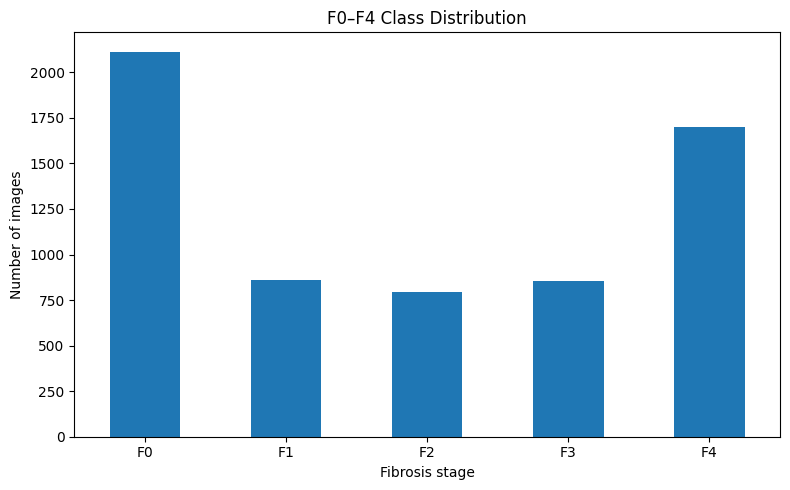

In [ ]:
# Dataset distribution plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8,5))
summary["count"].plot(kind="bar", ax=ax)
ax.set_title("F0–F4 Class Distribution")
ax.set_xlabel("Fibrosis stage")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(PROJECT_ROOT/"dataset_class_distribution.png", dpi=200)
plt.show()


## 3. Leakage-safe split

Default: **70% train / 15% validation / 15% test**, group-aware by filename stem.

The test set is held out until final evaluation. All augmentation is applied only to training images.


In [ ]:
train_df, val_df, test_df = leakage_safe_split(df, test_size=0.15, val_size=0.15, seed=CFG["seed"])

print("Split sizes:", len(train_df), len(val_df), len(test_df))
for name, part in [("Train",train_df),("Validation",val_df),("Test",test_df)]:
    print(f"\n{name}")
    display(part["label"].value_counts().reindex(CLASSES, fill_value=0).rename("count").to_frame())

# Save manifests so the exact split can be reproduced.
for name, part in [("train",train_df),("val",val_df),("test",test_df)]:
    part.to_csv(PROJECT_ROOT/f"{name}_split.csv", index=False)


Split sizes: 4426 948 949

Train


,count
label,
F0,1457
F1,605
F2,570
F3,603
F4,1191



Validation


,count
label,
F0,341
F1,117
F2,124
F3,134
F4,232



Test


,count
label,
F0,316
F1,139
F2,99
F3,120
F4,275


## 4. Preprocessing + augmentation




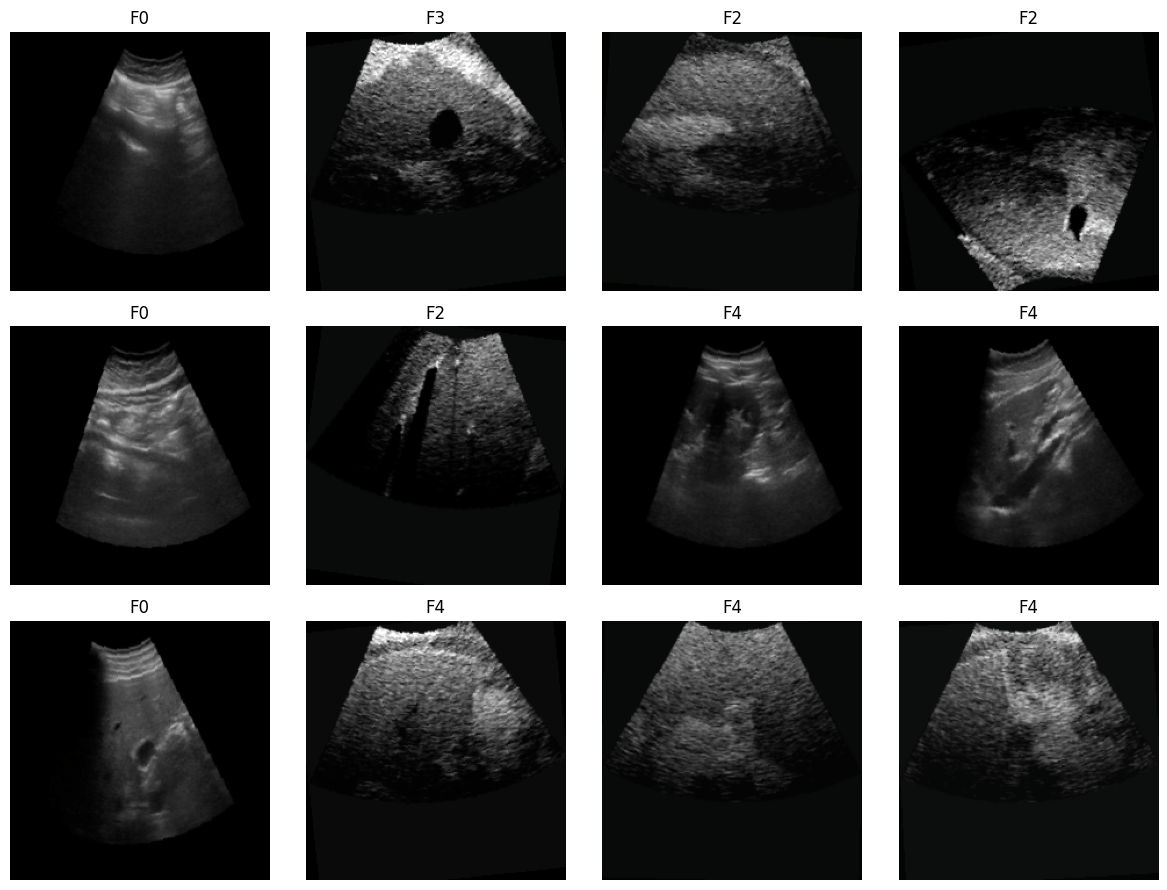

In [ ]:
train_tf, eval_tf = make_transforms(CFG["img_size"])
aug_ds = FibrosisDataset(train_df.sample(min(12,len(train_df)), random_state=CFG["seed"]), train_tf)

# Visualize augmented examples after inverse normalization.
mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])

fig, axes = plt.subplots(3,4,figsize=(12,9))
for ax, (x,y,p) in zip(axes.ravel(), [aug_ds[i] for i in range(min(12,len(aug_ds)))]):
    img = x.permute(1,2,0).numpy()*std + mean
    img = np.clip(img,0,1)
    ax.imshow(img)
    ax.set_title(CLASSES[y])
    ax.axis("off")
plt.tight_layout()
plt.savefig(PROJECT_ROOT/"augmentation_examples.png", dpi=200)
plt.show()


## 5. Imbalance handling experiment



In [ ]:
if CFG["run_imbalance"]:
    imbalance_results=[]
    strategies=["ce","class_weights","weighted_sampler","focal"]
    for strategy in strategies:
        print("\n===== Imbalance strategy:", strategy, "=====")
        local_cfg=dict(CFG); local_cfg["epochs"]=CFG["imbalance_epochs"]
        train_tf, eval_tf = make_transforms(CFG["img_size"])

        current_loss_strategy = strategy
        sampler = None
        if strategy=="weighted_sampler":
            sampler = make_weighted_sampler(train_df)
            current_loss_strategy = "ce" # When using weighted sampler, use CE loss.

        tr=make_loader(train_df,train_tf,CFG["batch_size"],shuffle=True,sampler=sampler,workers=CFG["workers"])
        va=make_loader(val_df,eval_tf,CFG["batch_size"],shuffle=False,workers=CFG["workers"])
        model=build_model("EfficientNet-B3",pretrained=CFG["pretrained"]).to(DEVICE)
        model,hist=train_one(model,tr,va,current_loss_strategy,train_df,DEVICE,epochs=CFG["imbalance_epochs"],lr=CFG["lr"],patience=2)
        vy,vp,_=predict(model,va,DEVICE)
        vm,_,_=classification_metrics(vy,vp)
        imbalance_results.append({"Strategy":strategy,**vm})
        del model,tr,va
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    imbalance_df=pd.DataFrame(imbalance_results).sort_values(
        ["Macro_F1","Balanced_Accuracy","Recall_macro"],ascending=False
    )
    display(imbalance_df)
    imbalance_df.to_csv(PROJECT_ROOT/"imbalance_strategy_results.csv",index=False)
    BEST_STRATEGY=str(imbalance_df.iloc[0]["Strategy"])
else:
    BEST_STRATEGY="class_weights"

print("Selected imbalance strategy:", BEST_STRATEGY)


===== Imbalance strategy: ce =====
Epoch 1/3 | loss=1.2529 | val F1=0.6035
Epoch 2/3 | loss=0.6593 | val F1=0.7549
Epoch 3/3 | loss=0.5461 | val F1=0.7559

===== Imbalance strategy: class_weights =====
Epoch 1/3 | loss=1.4126 | val F1=0.6359
Epoch 2/3 | loss=0.8156 | val F1=0.7214
Epoch 3/3 | loss=0.6685 | val F1=0.7437

===== Imbalance strategy: weighted_sampler =====
Epoch 1/3 | loss=1.3878 | val F1=0.5881
Epoch 2/3 | loss=0.7354 | val F1=0.7498
Epoch 3/3 | loss=0.5988 | val F1=0.7926

===== Imbalance strategy: focal =====
Epoch 1/3 | loss=0.9691 | val F1=0.5479
Epoch 2/3 | loss=0.4871 | val F1=0.6223
Epoch 3/3 | loss=0.3833 | val F1=0.6861


,Strategy,Accuracy,Precision_macro,Recall_macro,Specificity_macro,Macro_F1,Weighted_F1,Balanced_Accuracy,ROC_AUC_macro,PR_AUC_macro,ECE,Brier_Score
2,weighted_sampler,0.841772,0.795922,0.796204,0.962455,0.792582,0.845375,0.796204,0.965065,0.851418,0.027407,0.228411
0,ce,0.821730,0.762241,0.752914,0.956920,0.755946,0.819564,0.752914,0.957554,0.813694,0.033213,0.246888
1,class_weights,0.808017,0.747551,0.741860,0.953658,0.743650,0.807771,0.741860,0.962627,0.829662,0.031517,0.245661
3,focal,0.752110,0.686177,0.694960,0.940828,0.686069,0.755261,0.694960,0.938965,0.761454,0.045345,0.319317


Selected imbalance strategy: weighted_sampler


## 6–7. Main CNN, Transformer and Hybrid models

Models:

- ResNet50
- DenseNet121
- EfficientNet-B3
- ViT-B/16
- Swin Transformer (Swin-Tiny, 224×224)
- Proposed Hybrid: EfficientNet-B3 + Swin-Tiny → feature concatenation → fusion MLP → F0–F4 classifier

The hybrid is intentionally implemented as an actual feature-fusion model, not an ensemble of probabilities.


In [ ]:
MODEL_NAMES = ["ResNet50","DenseNet121","EfficientNet-B3","ViT-B/16","Swin","Hybrid"]
main_results=[]
artifacts={}
if CFG["run_all_models"]:
    for name in MODEL_NAMES:
        print("\n" + "="*70 + "\nTRAINING:", name, "| strategy:", BEST_STRATEGY)
        try:
            # Determine the actual loss strategy to use with run_training
            loss_strategy_for_training = BEST_STRATEGY
            if BEST_STRATEGY == "weighted_sampler":
                loss_strategy_for_training = "ce" # Use Cross Entropy loss when weighted_sampler is used

            model,hist,metrics,perclass,cm,pred_pack = run_training(
                name,loss_strategy_for_training,train_df,val_df,test_df,CFG,DEVICE
            )
            main_results.append(metrics)
            artifacts[name]={"model":model,"history":hist,"perclass":perclass,"cm":cm,"pred":pred_pack}
            hist.to_csv(PROJECT_ROOT/f"{name.replace('/','_')}_history.csv",index=False)
            perclass.to_csv(PROJECT_ROOT/f"{name.replace('/','_')}_per_class.csv",index=False)
            if CFG["save_checkpoints"]:
                save_checkpoint(model,PROJECT_ROOT/"checkpoints"/f"{name.replace('/','_')}.pt",
                                {"model":name,"strategy":BEST_STRATEGY,"classes":CLASSES,"img_size":CFG["img_size"]})
        except RuntimeError as e:
            print("Model failed:", name, e)
            if "out of memory" in str(e).lower():
                print("Try batch_size=16 or 8 and rerun this model.")
            raise
    results_df=pd.DataFrame(main_results).sort_values("Macro_F1",ascending=False)
    display(results_df)
    results_df.to_csv(PROJECT_ROOT/"main_model_results.csv",index=False)
else:
    results_df=pd.DataFrame()


TRAINING: ResNet50 | strategy: weighted_sampler
Epoch 1/8 | loss=1.2880 | val F1=0.2452
Epoch 2/8 | loss=0.9929 | val F1=0.3287
Epoch 3/8 | loss=0.8375 | val F1=0.4715
Epoch 4/8 | loss=0.7231 | val F1=0.5783
Epoch 5/8 | loss=0.6540 | val F1=0.5987
Epoch 6/8 | loss=0.6120 | val F1=0.6591
Epoch 7/8 | loss=0.5849 | val F1=0.6668
Epoch 8/8 | loss=0.5734 | val F1=0.6731

TRAINING: DenseNet121 | strategy: weighted_sampler


model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/8 | loss=0.9218 | val F1=0.5956
Epoch 2/8 | loss=0.6067 | val F1=0.7323
Epoch 3/8 | loss=0.4398 | val F1=0.8275
Epoch 4/8 | loss=0.3416 | val F1=0.8691
Epoch 5/8 | loss=0.2450 | val F1=0.9092
Epoch 6/8 | loss=0.1972 | val F1=0.9244
Epoch 7/8 | loss=0.1592 | val F1=0.9483
Epoch 8/8 | loss=0.1384 | val F1=0.9483

TRAINING: EfficientNet-B3 | strategy: weighted_sampler
Epoch 1/8 | loss=1.2808 | val F1=0.6584
Epoch 2/8 | loss=0.7127 | val F1=0.7324
Epoch 3/8 | loss=0.5209 | val F1=0.7390
Epoch 4/8 | loss=0.4234 | val F1=0.7988
Epoch 5/8 | loss=0.3339 | val F1=0.8539
Epoch 6/8 | loss=0.2987 | val F1=0.8548
Epoch 7/8 | loss=0.2550 | val F1=0.8586
Epoch 8/8 | loss=0.2395 | val F1=0.8597

TRAINING: ViT-B/16 | strategy: weighted_sampler


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/8 | loss=1.0966 | val F1=0.4140
Epoch 2/8 | loss=0.8052 | val F1=0.4702
Epoch 3/8 | loss=0.6913 | val F1=0.6339
Epoch 4/8 | loss=0.5637 | val F1=0.6835
Epoch 5/8 | loss=0.4364 | val F1=0.8044
Epoch 6/8 | loss=0.3253 | val F1=0.8704
Epoch 7/8 | loss=0.1963 | val F1=0.9158
Epoch 8/8 | loss=0.1374 | val F1=0.9371

TRAINING: Swin | strategy: weighted_sampler


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/8 | loss=0.9161 | val F1=0.6150
Epoch 2/8 | loss=0.6138 | val F1=0.7083
Epoch 3/8 | loss=0.4851 | val F1=0.8022
Epoch 4/8 | loss=0.3629 | val F1=0.8294
Epoch 5/8 | loss=0.2611 | val F1=0.8664
Epoch 6/8 | loss=0.1802 | val F1=0.9206
Epoch 7/8 | loss=0.1254 | val F1=0.9403
Epoch 8/8 | loss=0.0977 | val F1=0.9447

TRAINING: Hybrid | strategy: weighted_sampler
Epoch 1/8 | loss=0.8913 | val F1=0.6503
Epoch 2/8 | loss=0.5433 | val F1=0.7533
Epoch 3/8 | loss=0.3944 | val F1=0.8285
Epoch 4/8 | loss=0.2952 | val F1=0.9198
Epoch 5/8 | loss=0.1993 | val F1=0.9219
Epoch 6/8 | loss=0.1282 | val F1=0.9538
Epoch 7/8 | loss=0.0984 | val F1=0.9593
Epoch 8/8 | loss=0.0766 | val F1=0.9605


,Accuracy,Precision_macro,Recall_macro,Specificity_macro,Macro_F1,Weighted_F1,Balanced_Accuracy,ROC_AUC_macro,PR_AUC_macro,ECE,Brier_Score,Model,Strategy,Parameters,Training_seconds,Inference_seconds_total,Inference_ms_per_image
5,0.968388,0.952263,0.953268,0.992642,0.950933,0.968462,0.953268,0.995977,0.975094,0.012031,0.047147,Hybrid,ce,39398311,900.574608,7.167108,7.552274
1,0.956797,0.935904,0.934885,0.989752,0.935052,0.956644,0.934885,0.997161,0.982107,0.024417,0.059016,DenseNet121,ce,6958981,419.605169,4.728396,4.982503
4,0.950474,0.925577,0.924436,0.988324,0.924204,0.950232,0.924436,0.994807,0.975312,0.020038,0.070507,Swin,ce,27523199,531.845422,5.732260,6.040316
3,0.944152,0.914570,0.912287,0.986869,0.912611,0.943724,0.912287,0.992852,0.961273,0.020710,0.085269,ViT-B/16,ce,85802501,1346.734473,11.511236,12.129859
2,0.900948,0.858300,0.852695,0.976169,0.854476,0.900292,0.852695,0.986181,0.923620,0.033961,0.133328,EfficientNet-B3,ce,10703917,407.563626,5.609845,5.911323
0,0.792413,0.736195,0.690322,0.950158,0.686296,0.786632,0.690322,0.950624,0.785813,0.049979,0.267523,ResNet50,ce,23518277,434.458975,5.858442,6.173280


## 8. Main evaluation




--- Confusion Matrices (Raw & Normalized) ---


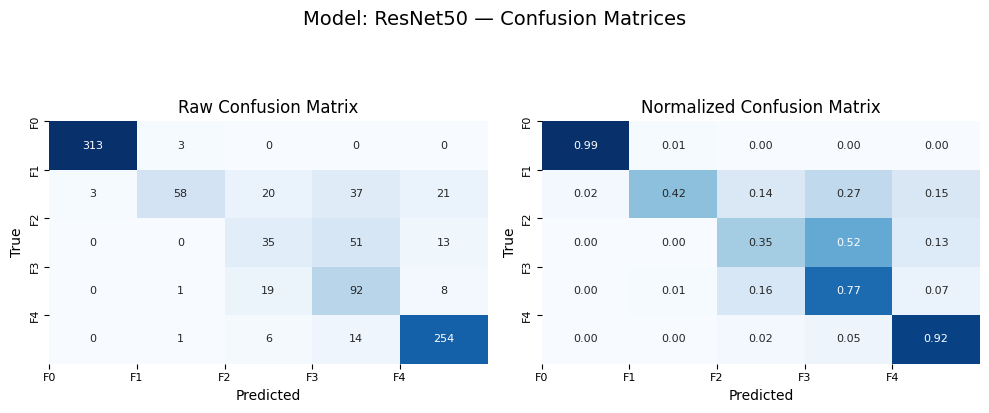

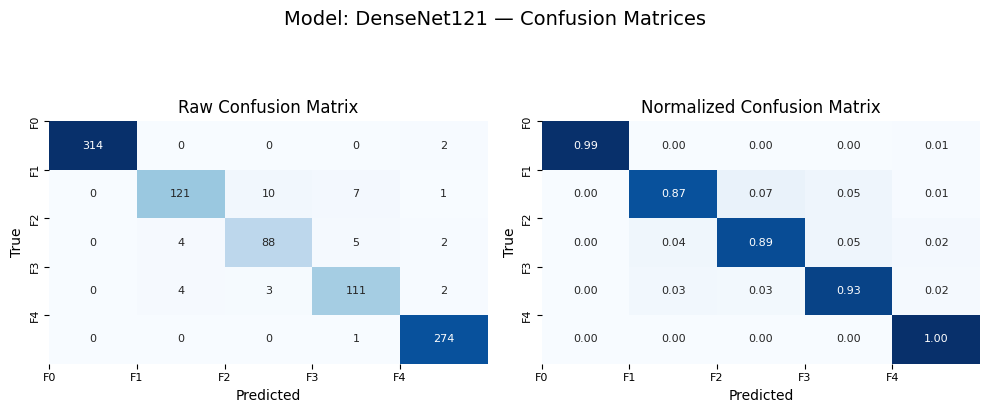

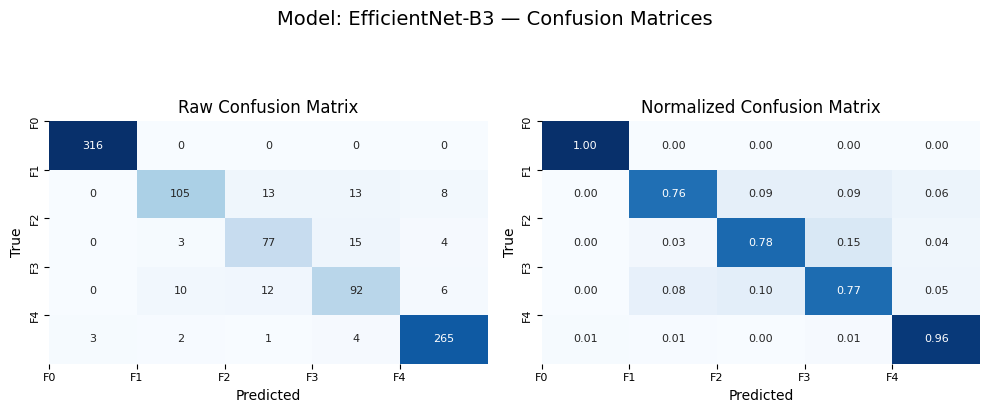

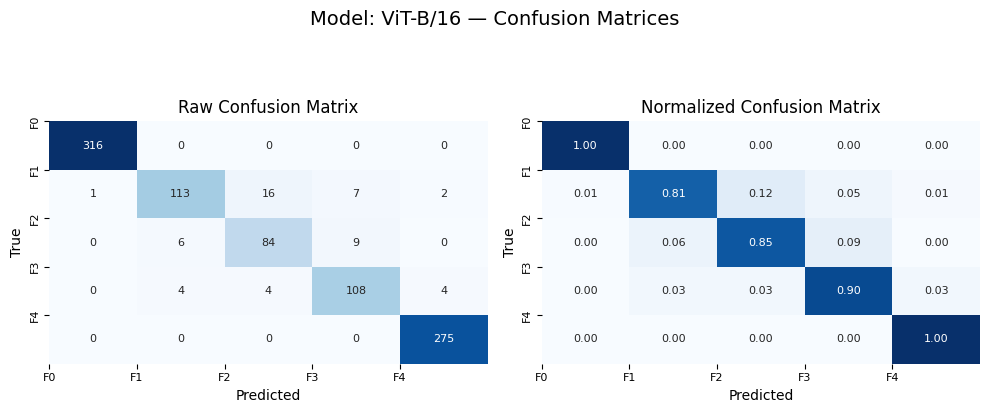

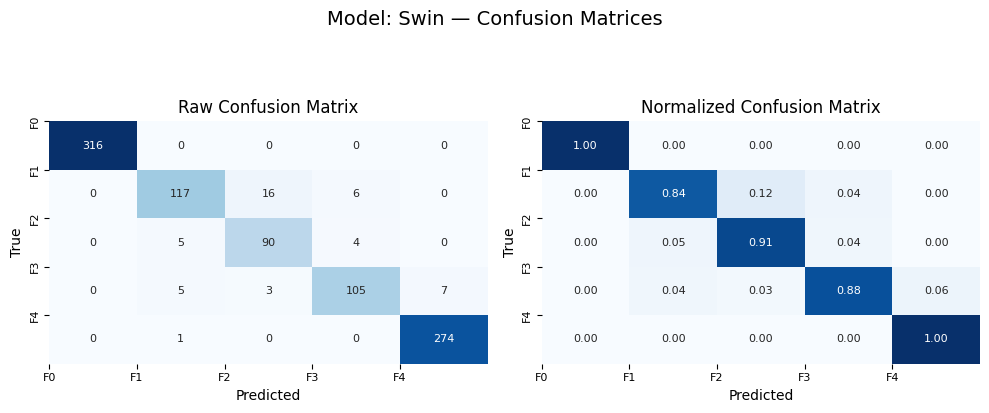

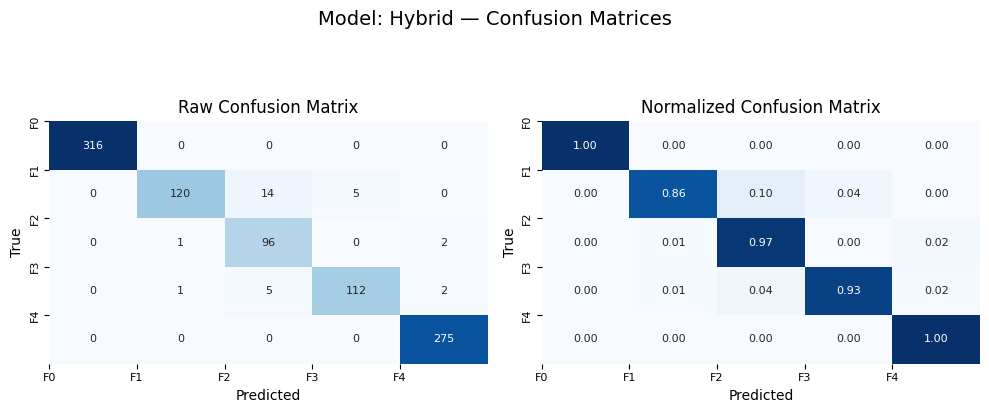


--- ROC-AUC & PR-AUC Curves ---


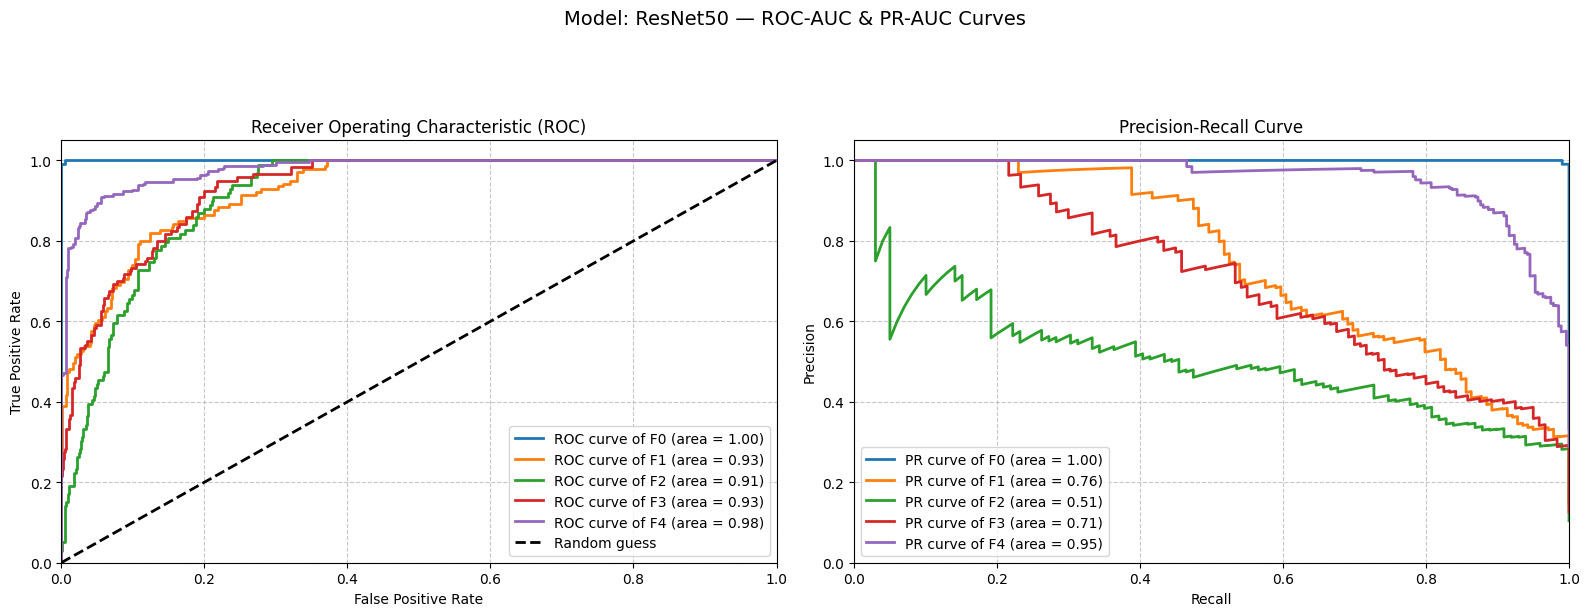

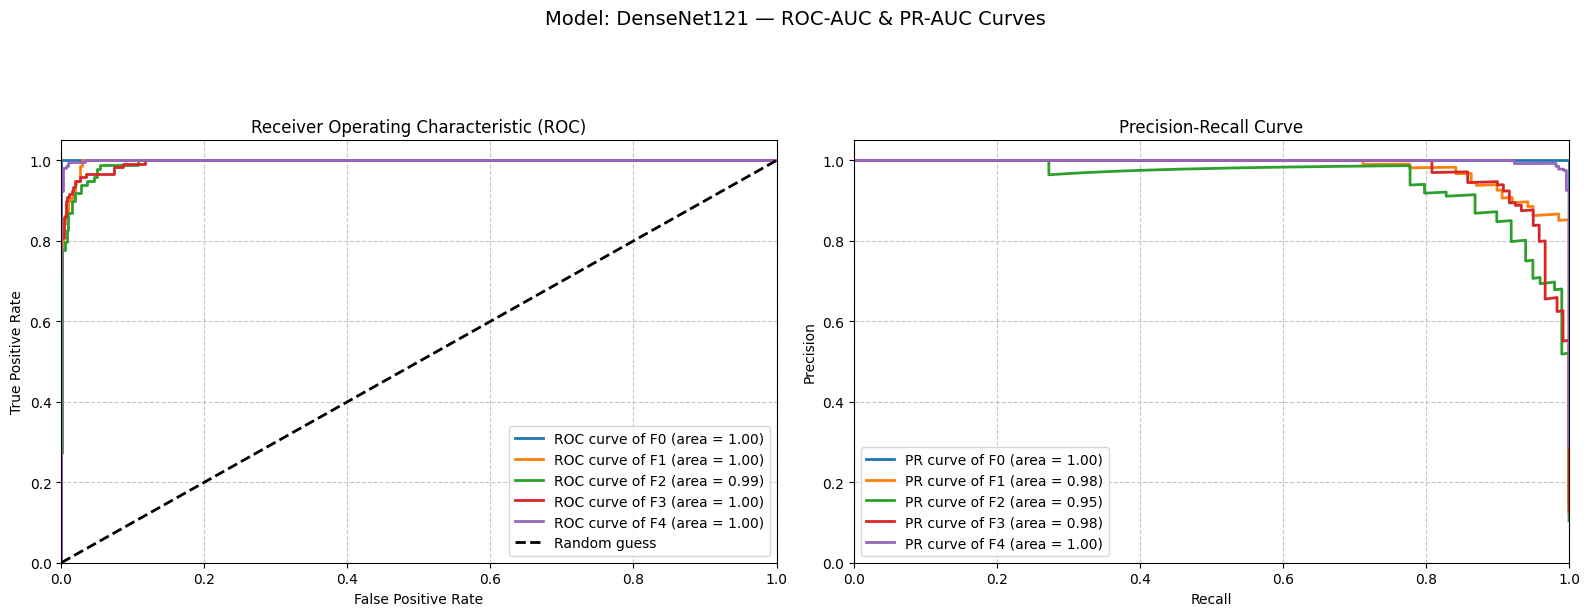

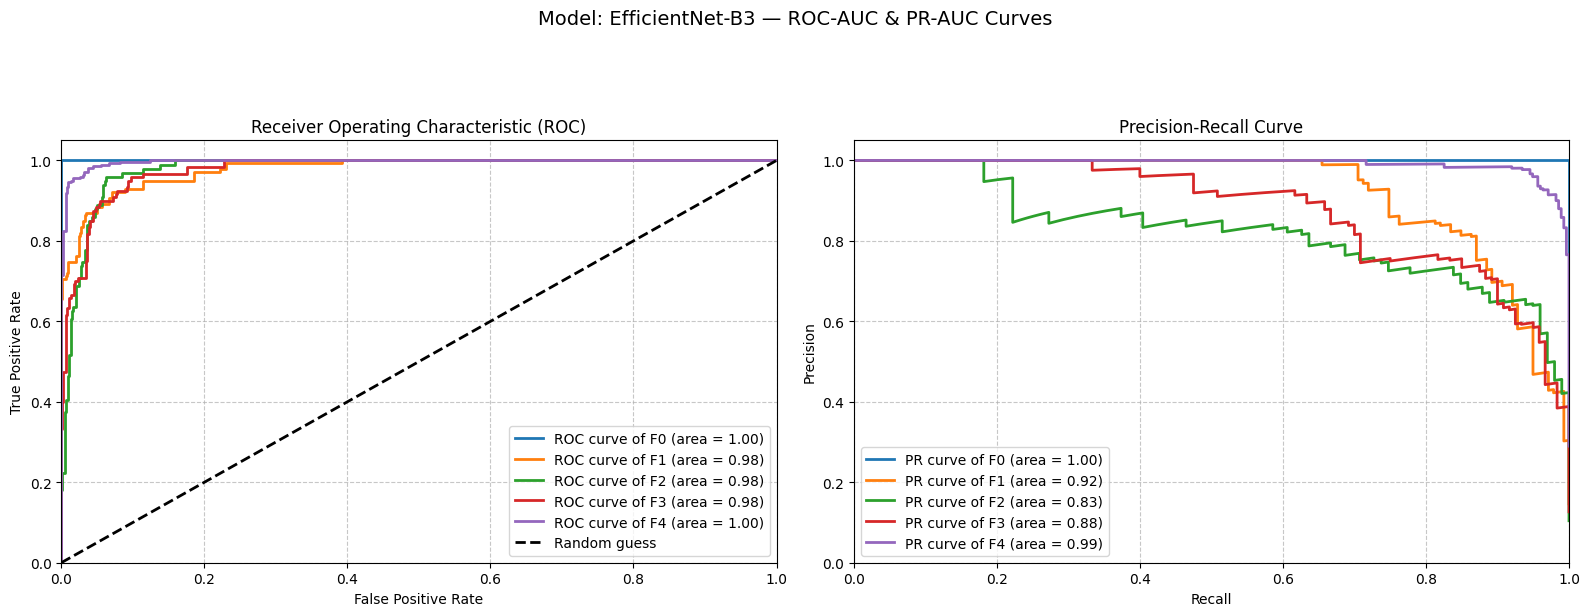

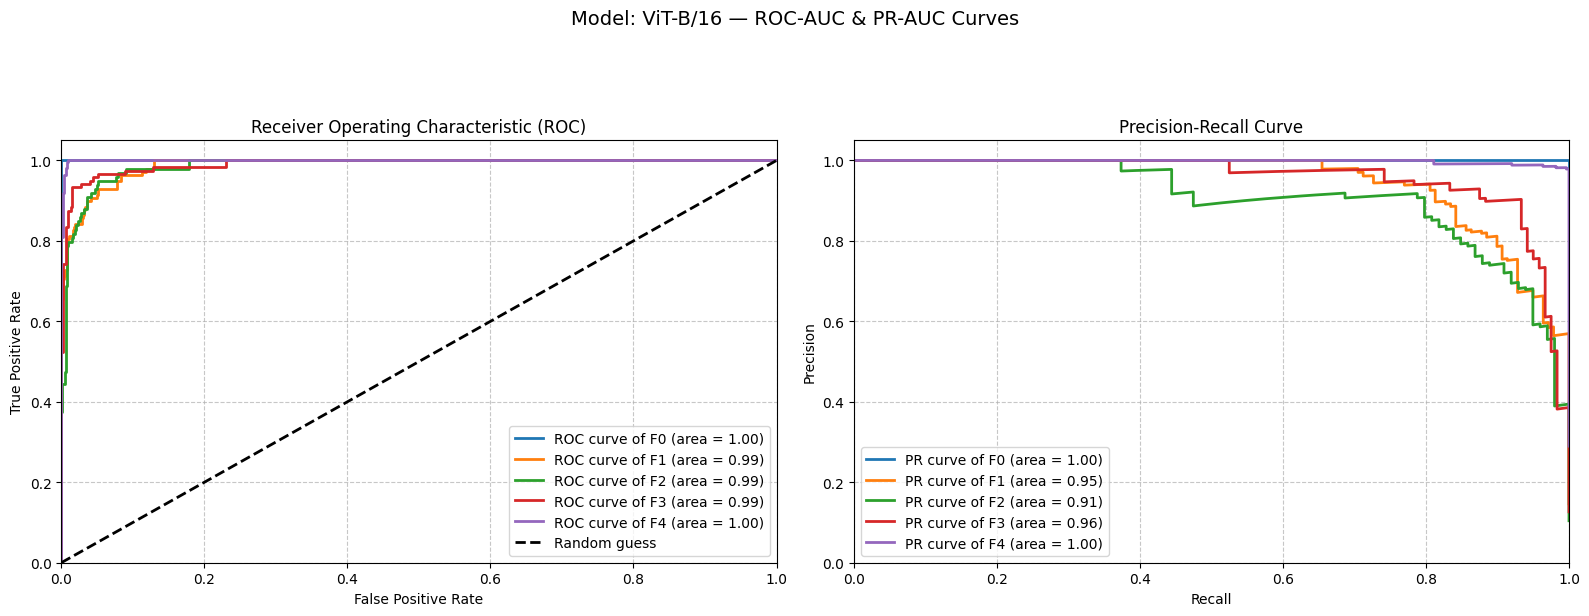

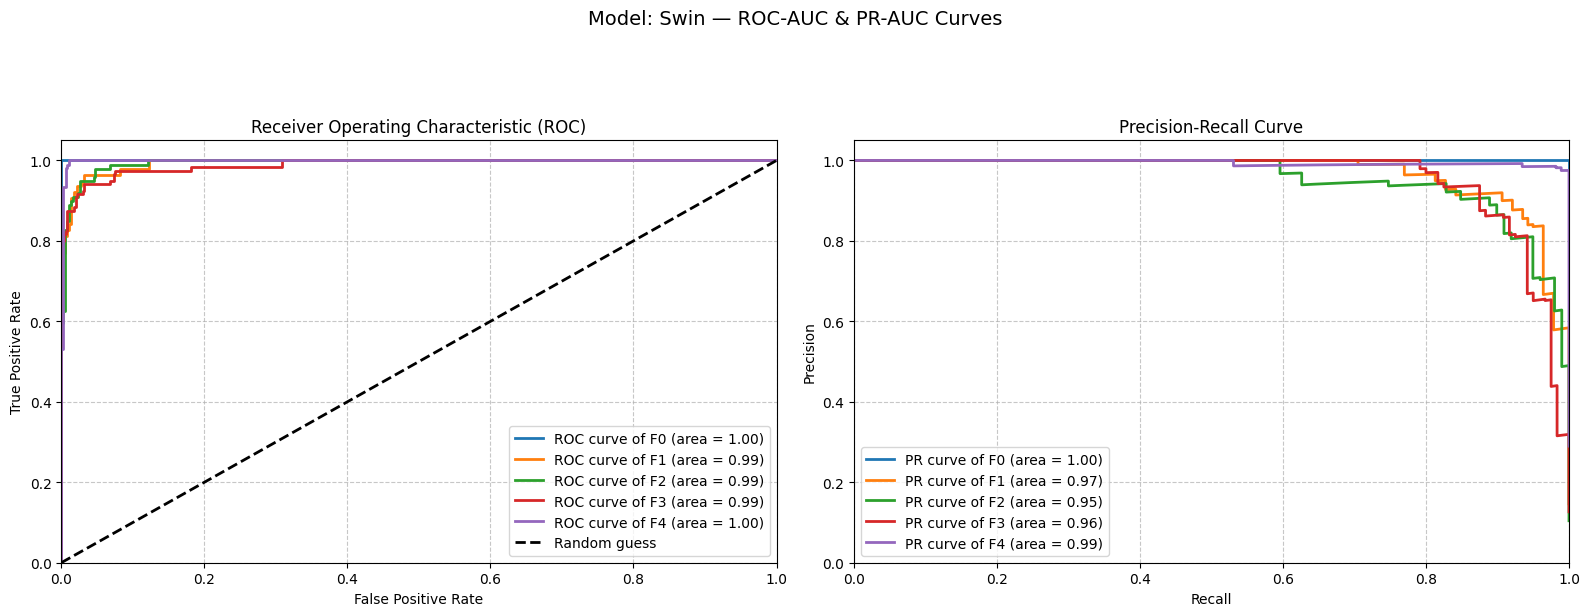

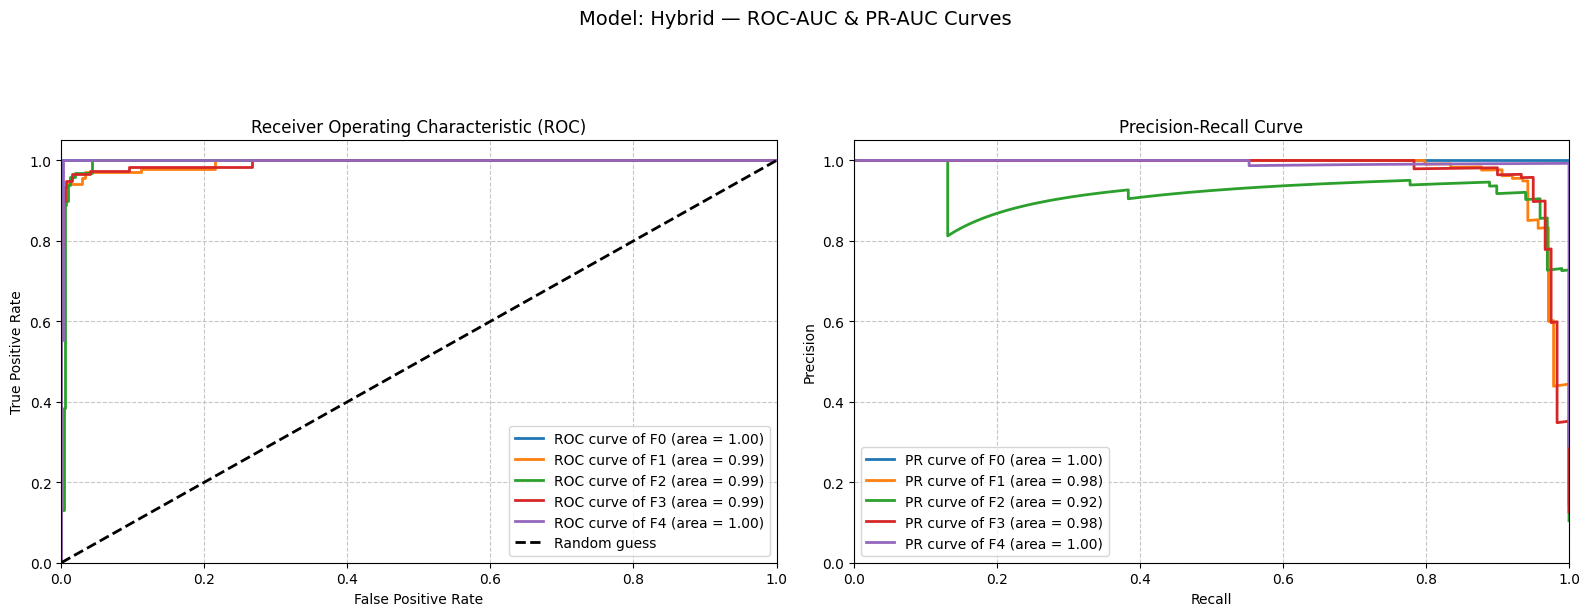

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import LabelBinarizer
import numpy as np # Ensure numpy is imported for nan_to_num

if CFG["run_all_models"]:
    print("\n--- Confusion Matrices (Raw & Normalized) ---")
    for name, a in artifacts.items():
        fig, axes = plt.subplots(1, 2, figsize=(10, 4)) # 1 row, 2 columns, compact size
        fig.suptitle(f"Model: {name} — Confusion Matrices", fontsize=14, y=1.05) # Overall model title

        # --- Raw Confusion Matrix (Left Subplot) ---
        ax0 = axes[0]
        sns.heatmap(a["cm"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax0, annot_kws={"size": 8})
        ax0.set_title("Raw Confusion Matrix", fontsize=12)
        ax0.set_xlabel("Predicted", fontsize=10)
        ax0.set_ylabel("True", fontsize=10)
        ax0.set_xticks(range(len(CLASSES)), CLASSES, fontsize=8)
        ax0.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)


        # --- Normalized Confusion Matrix (Right Subplot) ---
        ax1 = axes[1]
        cm_normalized = a["cm"].astype('float') / a["cm"].sum(axis=1)[:, np.newaxis]
        cm_normalized = np.nan_to_num(cm_normalized, nan=0.0) # Handle cases where a row sum is 0

        sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax1, annot_kws={"size": 8})
        ax1.set_title("Normalized Confusion Matrix", fontsize=12)
        ax1.set_xlabel("Predicted", fontsize=10)
        ax1.set_ylabel("True", fontsize=10)
        ax1.set_xticks(range(len(CLASSES)), CLASSES, fontsize=8)
        ax1.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)


        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap

        # Save in both JPG and PNG
        filename_base = PROJECT_ROOT / f"{name.replace('/','_')}_confusion_matrices"
        plt.savefig(f"{filename_base}.jpg", dpi=300, bbox_inches="tight")
        plt.savefig(f"{filename_base}.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    print("\n--- ROC-AUC & PR-AUC Curves ---")
    lb = LabelBinarizer()
    for name, a in artifacts.items():
        y_true = a["pred"][0]
        y_prob = a["pred"][1]
        y_true_binarized = lb.fit_transform(y_true)

        fig, axes = plt.subplots(1, 2, figsize=(16, 6)) # Adjust figsize for two plots
        fig.suptitle(f"Model: {name} — ROC-AUC & PR-AUC Curves", fontsize=14, y=1.05)

        # --- ROC-AUC Curve (Left Subplot) ---
        ax0 = axes[0]
        for i, class_name in enumerate(CLASSES):
            fpr, tpr, _ = roc_curve(y_true_binarized[:, i], y_prob[:, i])
            roc_auc = auc(fpr, tpr)
            ax0.plot(fpr, tpr, lw=2, label=f'ROC curve of {class_name} (area = {roc_auc:.2f})')

        ax0.plot([0, 1], [0, 1], 'k--', lw=2, label='Random guess')
        ax0.set_xlim([0.0, 1.0])
        ax0.set_ylim([0.0, 1.05])
        ax0.set_xlabel('False Positive Rate')
        ax0.set_ylabel('True Positive Rate')
        ax0.set_title('Receiver Operating Characteristic (ROC)', fontsize=12)
        ax0.legend(loc="lower right")
        ax0.grid(True, linestyle='--', alpha=0.7)

        # --- PR-AUC Curve (Right Subplot) ---
        ax1 = axes[1]
        for i, class_name in enumerate(CLASSES):
            precision, recall, _ = precision_recall_curve(y_true_binarized[:, i], y_prob[:, i])
            pr_auc = average_precision_score(y_true_binarized[:, i], y_prob[:, i])
            ax1.plot(recall, precision, lw=2, label=f'PR curve of {class_name} (area = {pr_auc:.2f})')

        ax1.set_xlim([0.0, 1.0])
        ax1.set_ylim([0.0, 1.05])
        ax1.set_xlabel('Recall')
        ax1.set_ylabel('Precision')
        ax1.set_title('Precision-Recall Curve', fontsize=12)
        ax1.legend(loc="lower left")
        ax1.grid(True, linestyle='--', alpha=0.7)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        filename_base = PROJECT_ROOT / f"{name.replace('/','_')}_roc_pr_curves"
        plt.savefig(f"{filename_base}.png", dpi=200)
        plt.show()
        plt.close(fig)

else:
    print("Set CFG['run_all_models']=True to run main evaluation metrics.")

## 9. Calibration analysis




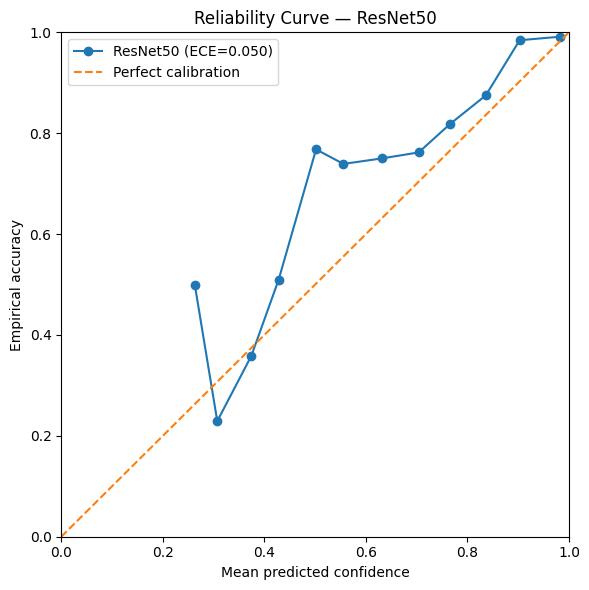

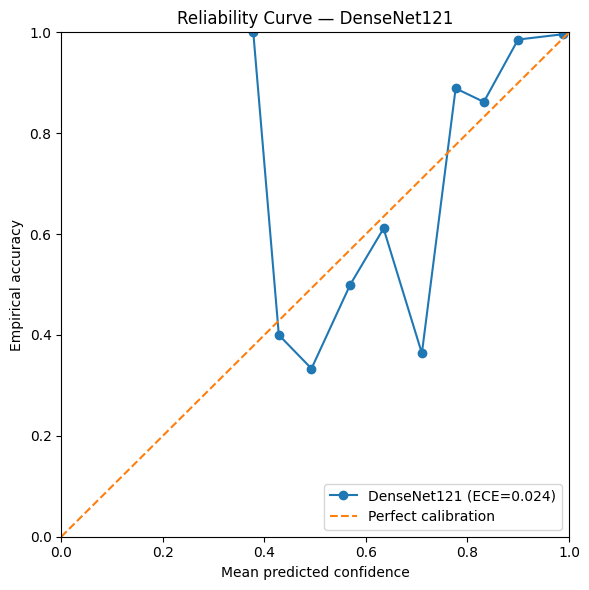

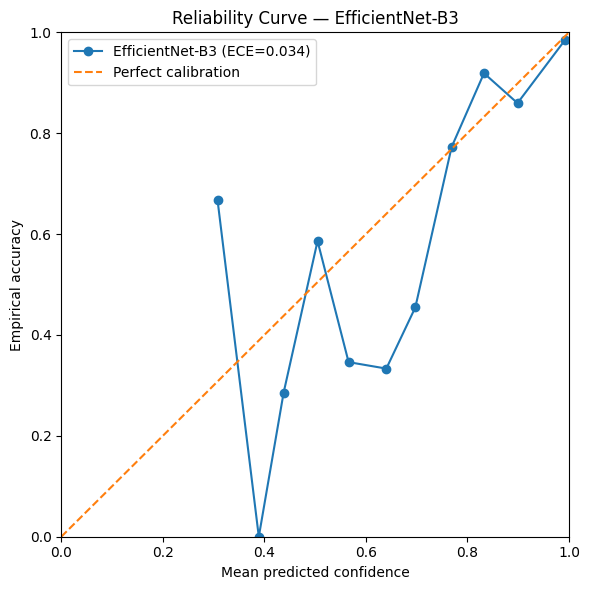

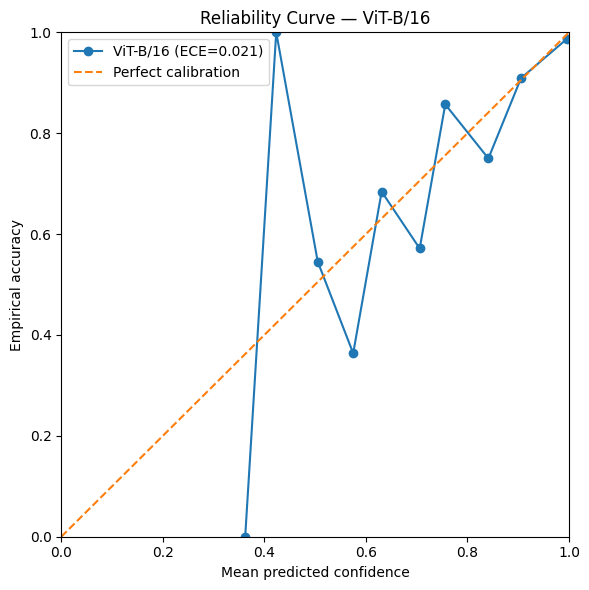

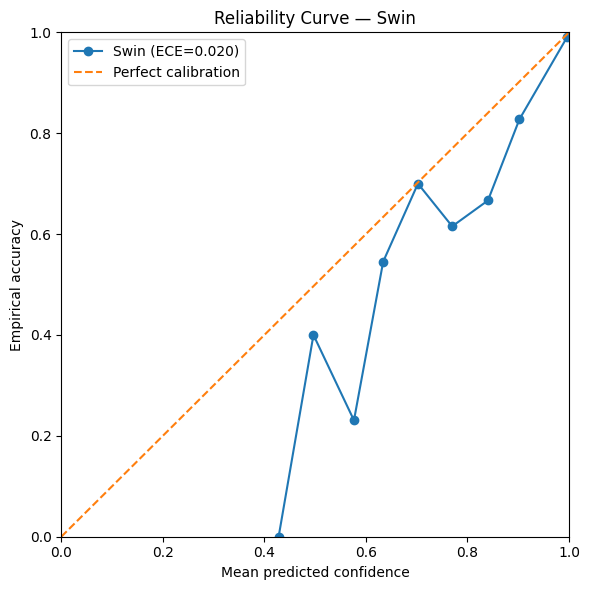

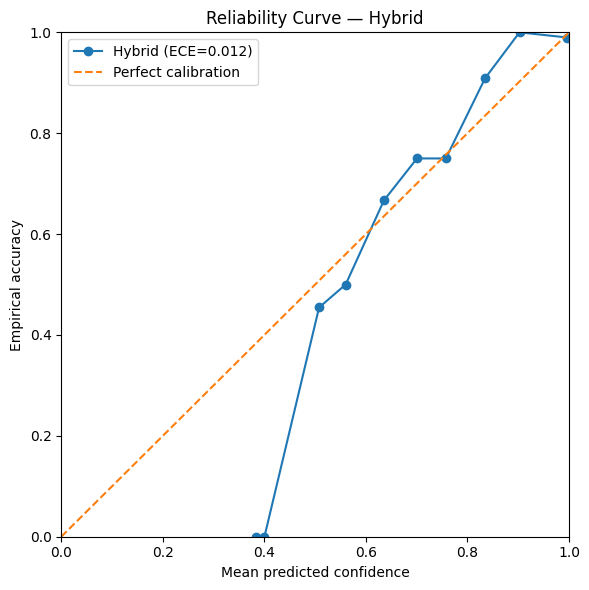

,Model,ECE,Brier_Score
5,Hybrid,0.012031,0.047147
4,Swin,0.020038,0.070507
3,ViT-B/16,0.020710,0.085269
1,DenseNet121,0.024417,0.059016
2,EfficientNet-B3,0.033961,0.133328
0,ResNet50,0.049979,0.267523


In [ ]:
def plot_reliability(name, y_true, probs):
    ece, rel = ece_score(y_true,probs,n_bins=15)
    fig, ax = plt.subplots(figsize=(6,6))
    if len(rel):
        ax.plot(rel["confidence"],rel["accuracy"],marker="o",label=f"{name} (ECE={ece:.3f})")
    ax.plot([0,1],[0,1],linestyle="--",label="Perfect calibration")
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel("Mean predicted confidence")
    ax.set_ylabel("Empirical accuracy")
    ax.set_title(f"Reliability Curve — {name}")
    ax.legend()
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT/f"{name.replace('/','_')}_reliability_curve.png",dpi=200)
    plt.show()

if CFG["run_all_models"]:
    calibration_rows=[]
    for name,a in artifacts.items():
        y,p,_=a["pred"]
        ece,rel=ece_score(y,p)
        brier=multiclass_brier(y,p)
        calibration_rows.append({"Model":name,"ECE":ece,"Brier_Score":brier})
        rel.to_csv(PROJECT_ROOT/f"{name.replace('/','_')}_reliability_bins.csv",index=False)
        plot_reliability(name,y,p)
    calibration_df=pd.DataFrame(calibration_rows).sort_values("ECE")
    display(calibration_df)
    calibration_df.to_csv(PROJECT_ROOT/"calibration_results.csv",index=False)


In [ ]:
# Temperature scaling helper
class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.temperature=nn.Parameter(torch.ones(1)*1.0)
    def forward(self, logits):
        return logits/self.temperature.clamp_min(1e-3)

# The base pipeline reports uncalibrated probabilities above.
# Post-hoc temperature fitting can be added to the final model if required.
print("Base calibration analysis complete: ECE + Brier + reliability curves.")


Base calibration analysis complete: ECE + Brier + reliability curves.


OVERALL MODEL COMPARISON


,Rank,Model,Accuracy,Precision_macro,Recall_macro,Specificity_macro,Macro_F1,Weighted_F1,Balanced_Accuracy,ROC_AUC_macro,PR_AUC_macro,ECE,Brier_Score,Parameters,Training_seconds,Inference_ms_per_image,Overall_Score
0,1,Hybrid,0.9684,0.9523,0.9533,0.9926,0.9509,0.9685,0.9533,0.9960,0.9751,0.0120,0.0471,39398311,900.574608,7.552274,99.4439
1,2,DenseNet121,0.9568,0.9359,0.9349,0.9898,0.9351,0.9566,0.9349,0.9972,0.9821,0.0244,0.0590,6958981,419.605169,4.982503,92.2300
2,3,Swin,0.9505,0.9256,0.9244,0.9883,0.9242,0.9502,0.9244,0.9948,0.9753,0.0200,0.0705,27523199,531.845422,6.040316,89.5477
3,4,ViT-B/16,0.9442,0.9146,0.9123,0.9869,0.9126,0.9437,0.9123,0.9929,0.9613,0.0207,0.0853,85802501,1346.734473,12.129859,85.0812
4,5,EfficientNet-B3,0.9009,0.8583,0.8527,0.9762,0.8545,0.9003,0.8527,0.9862,0.9236,0.0340,0.1333,10703917,407.563626,5.911323,61.6994
5,6,ResNet50,0.7924,0.7362,0.6903,0.9502,0.6863,0.7866,0.6903,0.9506,0.7858,0.0500,0.2675,23518277,434.458975,6.173280,0.0000


Primary ranking (Macro-F1 → Balanced Accuracy → calibration): Hybrid
Highest composite Overall Score: Hybrid


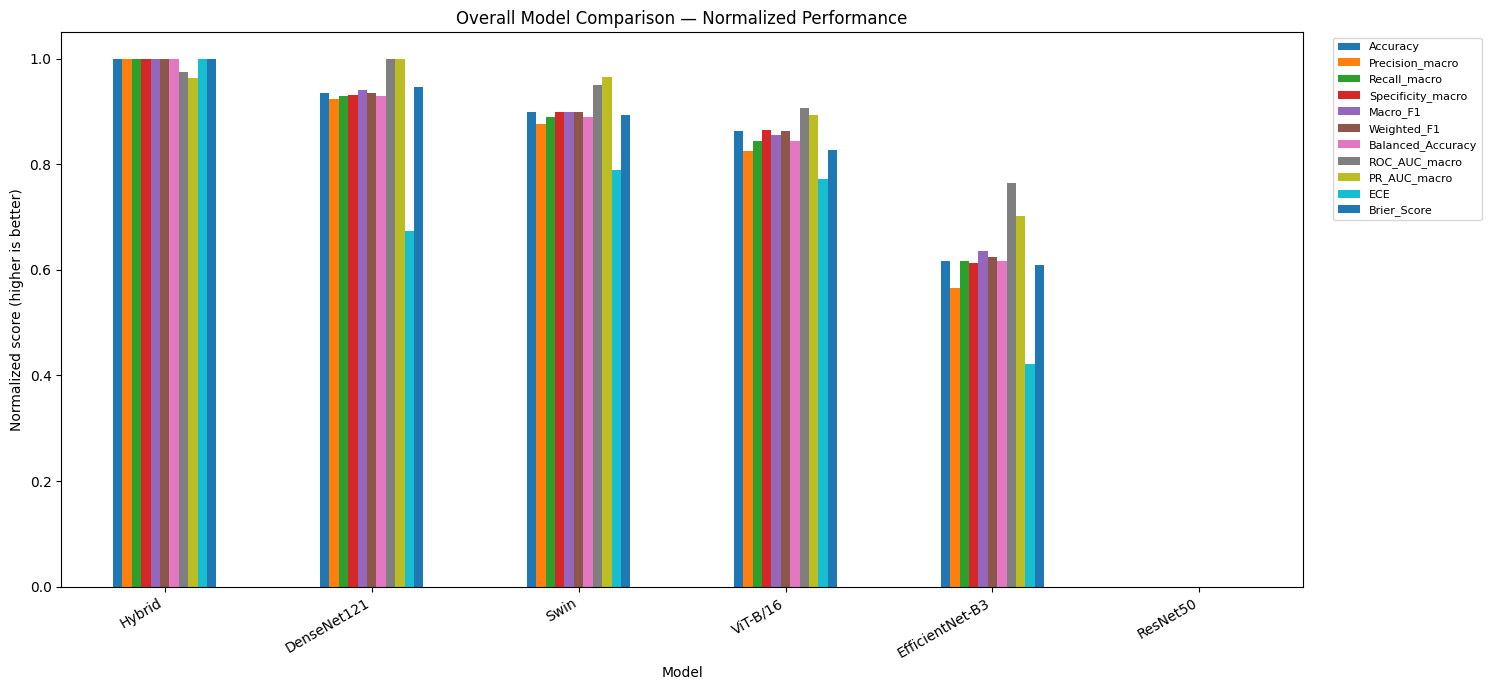

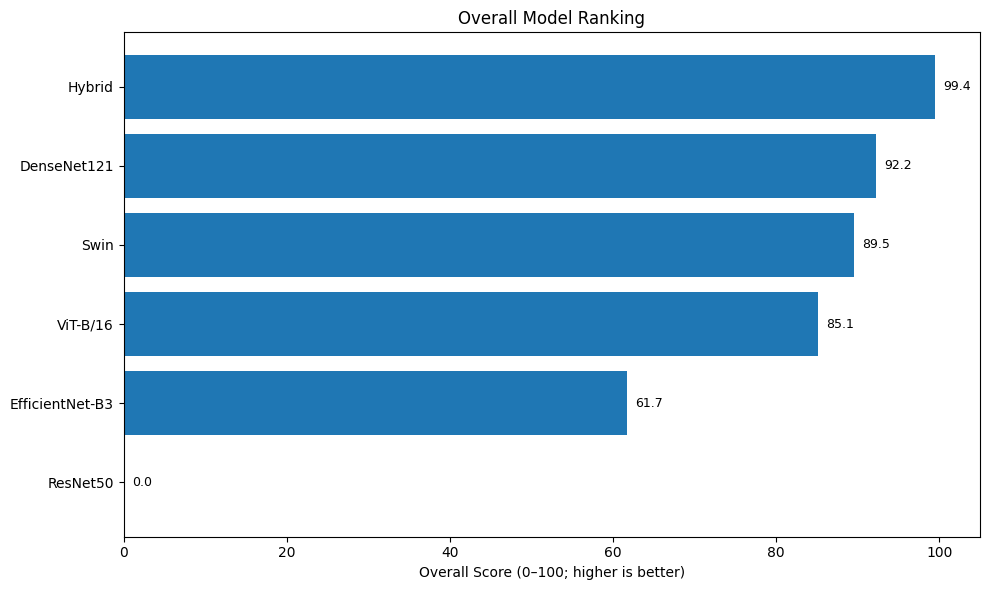

In [ ]:
if CFG["run_all_models"] and not results_df.empty:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    comparison_cols = [
        "Model","Accuracy","Precision_macro","Recall_macro","Specificity_macro",
        "Macro_F1","Weighted_F1","Balanced_Accuracy","ROC_AUC_macro","PR_AUC_macro",
        "ECE","Brier_Score","Parameters","Training_seconds","Inference_ms_per_image"
    ]
    comparison = results_df[comparison_cols].copy()

    # Higher is better metrics.
    benefit_metrics = [
        "Accuracy","Precision_macro","Recall_macro","Specificity_macro",
        "Macro_F1","Weighted_F1","Balanced_Accuracy","ROC_AUC_macro","PR_AUC_macro"
    ]
    # Lower is better metrics; invert their normalized values.
    cost_metrics = ["ECE","Brier_Score"]

    def minmax_benefit(s):
        s = pd.to_numeric(s, errors="coerce")
        lo, hi = s.min(), s.max()
        if pd.isna(lo) or pd.isna(hi) or hi == lo:
            return pd.Series(np.ones(len(s)), index=s.index)
        return (s - lo) / (hi - lo)

    score_parts = {}
    for m in benefit_metrics:
        score_parts[m] = minmax_benefit(comparison[m])
    for m in cost_metrics:
        score_parts[m] = 1.0 - minmax_benefit(comparison[m])

    score_df = pd.DataFrame(score_parts, index=comparison.index)
    comparison["Overall_Score"] = score_df.mean(axis=1) * 100

    # A transparent primary ranking: Macro-F1 first, then Balanced Accuracy,
    # then ECE/Brier as tie-breakers. Overall_Score is shown separately.
    comparison = comparison.sort_values(
        ["Macro_F1","Balanced_Accuracy","ECE","Brier_Score"],
        ascending=[False,False,True,True]
    ).reset_index(drop=True)
    comparison.insert(0, "Rank", np.arange(1, len(comparison)+1))

    # Save the full numerical table.
    comparison.to_csv(PROJECT_ROOT/"overall_model_comparison.csv", index=False)

    # Thesis-friendly rounded table.
    display_cols = [
        "Rank","Model","Accuracy","Precision_macro","Recall_macro",
        "Specificity_macro","Macro_F1","Weighted_F1","Balanced_Accuracy",
        "ROC_AUC_macro","PR_AUC_macro","ECE","Brier_Score",
        "Parameters","Training_seconds","Inference_ms_per_image","Overall_Score"
    ]
    thesis_table = comparison[display_cols].copy()
    for col in [
        "Accuracy","Precision_macro","Recall_macro","Specificity_macro",
        "Macro_F1","Weighted_F1","Balanced_Accuracy","ROC_AUC_macro",
        "PR_AUC_macro","ECE","Brier_Score","Overall_Score"
    ]:
        thesis_table[col] = thesis_table[col].map(lambda x: round(float(x), 4) if pd.notna(x) else x)

    print("OVERALL MODEL COMPARISON")
    display(thesis_table)

    # Identify best models using the actual primary metrics.
    best_primary = comparison.iloc[0]["Model"]
    best_overall_score = comparison.loc[comparison["Overall_Score"].idxmax(), "Model"]
    print(f"Primary ranking (Macro-F1 → Balanced Accuracy → calibration): {best_primary}")
    print(f"Highest composite Overall Score: {best_overall_score}")

    # ---- Graph 1: all major performance metrics, normalized to 0–1 ----
    plot_metrics = benefit_metrics + cost_metrics
    plot_df = pd.DataFrame(index=comparison["Model"])
    for m in benefit_metrics:
        plot_df[m] = minmax_benefit(comparison.set_index("Model")[m])
    for m in cost_metrics:
        plot_df[m] = 1.0 - minmax_benefit(comparison.set_index("Model")[m])

    ax = plot_df.plot(kind="bar", figsize=(15,7))
    ax.set_title("Overall Model Comparison — Normalized Performance")
    ax.set_xlabel("Model")
    ax.set_ylabel("Normalized score (higher is better)")
    ax.set_ylim(0, 1.05)
    ax.legend(bbox_to_anchor=(1.02,1), loc="upper left", fontsize=8)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT/"overall_model_comparison.png", dpi=250, bbox_inches="tight")
    plt.show()

    # ---- Graph 2: composite overall score ----
    ranking_plot = comparison.sort_values("Overall_Score", ascending=True)
    fig, ax = plt.subplots(figsize=(10,6))
    bars = ax.barh(ranking_plot["Model"], ranking_plot["Overall_Score"])
    ax.set_title("Overall Model Ranking")
    ax.set_xlabel("Overall Score (0–100; higher is better)")
    ax.set_xlim(0, 105)
    for bar, value in zip(bars, ranking_plot["Overall_Score"]):
        ax.text(value + 1, bar.get_y() + bar.get_height()/2, f"{value:.1f}",
                va="center", fontsize=9)
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT/"overall_model_ranking.png", dpi=250, bbox_inches="tight")
    plt.show()

    # Export the compact thesis table separately.
    thesis_table.to_csv(PROJECT_ROOT/"thesis_model_comparison_table.csv", index=False)

else:
    print("Enable CFG['run_all_models']=True and run the main evaluation first.")

## 10. Ablation study

Requested conceptual progression:

| Experiment | Architecture | Augmentation | Imbalance |
|---|---|---|---|
| E1 | CNN | No | CE |
| E2 | CNN | Yes | CE |
| E3 | CNN | Yes | Class weights |
| E4 | Transformer | Yes | Class weights |
| E5 | Hybrid | Yes | Class weights |
| E6 | Hybrid | Yes | Best method |

The full ablation is computationally expensive, so it is disabled by default. Set `CFG["run_full_ablation"]=True` to execute it. The code saves Macro-F1, Balanced Accuracy, ECE and Brier Score for each experiment.


## 11. Error Analysis



### 11.1. Overall Error Summary

This table summarizes the overall performance of each model in terms of correct and incorrect predictions on the test set.

In [ ]:
import pandas as pd
import numpy as np

overall_error_summary_rows = []

if CFG["run_all_models"] and artifacts:
    for model_name, data in artifacts.items():
        y_true, y_prob, _ = data["pred"]
        y_pred = np.argmax(y_prob, axis=1)

        total_test_images = len(y_true)
        correct_predictions = np.sum(y_true == y_pred)
        incorrect_predictions = total_test_images - correct_predictions
        error_rate = incorrect_predictions / total_test_images

        overall_error_summary_rows.append({
            "Model": model_name,
            "Total_Test_Images": total_test_images,
            "Correct": correct_predictions,
            "Incorrect": incorrect_predictions,
            "Error_Rate": f"{error_rate:.4f}"
        })

    overall_error_summary_df = pd.DataFrame(overall_error_summary_rows)
    display(overall_error_summary_df)
    overall_error_summary_df.to_csv(PROJECT_ROOT / "error_analysis_summary.csv", index=False)
else:
    print("Overall error summary requires CFG['run_all_models']=True and trained models in 'artifacts'.")


,Model,Total_Test_Images,Correct,Incorrect,Error_Rate
0,ResNet50,949,752,197,0.2076
1,DenseNet121,949,908,41,0.0432
2,EfficientNet-B3,949,855,94,0.0991
3,ViT-B/16,949,896,53,0.0558
4,Swin,949,902,47,0.0495
5,Hybrid,949,919,30,0.0316


### 11.2. Per-Class Error Analysis


In [ ]:
per_class_error_analysis_rows = []

if CFG["run_all_models"] and artifacts and CLASSES:
    for model_name, data in artifacts.items():
        y_true, y_prob, _ = data["pred"]
        y_pred = np.argmax(y_prob, axis=1)

        # Retrieve per-class metrics (including recall/sensitivity) from artifacts
        perclass_metrics = data["perclass"]

        for class_idx, class_name in enumerate(CLASSES):
            class_mask = (y_true == class_idx)
            total_samples_class = np.sum(class_mask)

            if total_samples_class > 0:
                correct_predictions_class = np.sum((y_true == class_idx) & (y_pred == class_idx))
                incorrect_predictions_class = total_samples_class - correct_predictions_class
                error_rate_class = incorrect_predictions_class / total_samples_class

                # Get recall from the already computed perclass_metrics
                recall_class = perclass_metrics.loc[perclass_metrics['class'] == class_name, 'recall'].iloc[0]

                per_class_error_analysis_rows.append({
                    "Model": model_name,
                    "Class": class_name,
                    "Total_Samples": total_samples_class,
                    "Correct_Predictions": correct_predictions_class,
                    "Incorrect_Predictions": incorrect_predictions_class,
                    "Error_Rate": f"{error_rate_class:.4f}",
                    "Recall": f"{recall_class:.4f}"
                })

    per_class_error_analysis_df = pd.DataFrame(per_class_error_analysis_rows)
    display(per_class_error_analysis_df)
    per_class_error_analysis_df.to_csv(PROJECT_ROOT / "per_class_error_analysis.csv", index=False)
else:
    print("Per-class error analysis requires CFG['run_all_models']=True, trained models, and CLASSES defined.")


,Model,Class,Total_Samples,Correct_Predictions,Incorrect_Predictions,Error_Rate,Recall
0,ResNet50,F0,316,313,3,0.0095,0.9905
1,ResNet50,F1,139,58,81,0.5827,0.4173
2,ResNet50,F2,99,35,64,0.6465,0.3535
3,ResNet50,F3,120,92,28,0.2333,0.7667
4,ResNet50,F4,275,254,21,0.0764,0.9236
5,DenseNet121,F0,316,314,2,0.0063,0.9937
6,DenseNet121,F1,139,121,18,0.1295,0.8705
7,DenseNet121,F2,99,88,11,0.1111,0.8889
8,DenseNet121,F3,120,111,9,0.0750,0.9250
9,DenseNet121,F4,275,274,1,0.0036,0.9964


### 11.3. Most Common Confusions


In [ ]:
import collections

most_common_confusions = []
adjacent_stage_confusions = []

if CFG["run_all_models"] and artifacts and CLASSES:
    for model_name, data in artifacts.items():
        y_true, y_prob, _ = data["pred"]
        y_pred = np.argmax(y_prob, axis=1)

        incorrect_indices = np.where(y_true != y_pred)[0]

        # Common confusions
        confusion_patterns = collections.defaultdict(int)
        for idx in incorrect_indices:
            true_class_name = CLASSES[y_true[idx]]
            predicted_class_name = CLASSES[y_pred[idx]]
            pattern = f"{true_class_name} -> {predicted_class_name}"
            confusion_patterns[pattern] += 1

        # Sort and get top 10
        sorted_confusions = sorted(confusion_patterns.items(), key=lambda item: item[1], reverse=True)
        for pattern, count in sorted_confusions[:10]:
            most_common_confusions.append({"Model": model_name, "Confusion_Pattern": pattern, "Frequency": count})

        # Adjacent-stage confusions
        model_adjacent_confusions = collections.defaultdict(int)
        for idx in incorrect_indices:
            true_class_idx = y_true[idx]
            predicted_class_idx = y_pred[idx]

            # Check for adjacent stages (e.g., F0 <-> F1, F1 <-> F2)
            if abs(true_class_idx - predicted_class_idx) == 1:
                # Standardize pattern for Fx <-> Fy, e.g., F0 <-> F1
                sorted_class_names = sorted([CLASSES[true_class_idx], CLASSES[predicted_class_idx]])
                pattern = f"{sorted_class_names[0]} <-> {sorted_class_names[1]}"
                model_adjacent_confusions[pattern] += 1

        for pattern, count in model_adjacent_confusions.items():
            adjacent_stage_confusions.append({"Model": model_name, "Adjacent_Confusion": pattern, "Frequency": count})

    most_common_confusions_df = pd.DataFrame(most_common_confusions)
    print("Most Common Confusion Patterns (Top 10 per model):")
    display(most_common_confusions_df)
    most_common_confusions_df.to_csv(PROJECT_ROOT / "most_common_confusions.csv", index=False)

    adjacent_stage_confusions_df = pd.DataFrame(adjacent_stage_confusions)
    print("\nAdjacent-Stage Confusion Summary:")
    display(adjacent_stage_confusions_df)
    adjacent_stage_confusions_df.to_csv(PROJECT_ROOT / "adjacent_stage_confusions.csv", index=False)
else:
    print("Confusion analysis requires CFG['run_all_models']=True, trained models, and CLASSES defined.")


Most Common Confusion Patterns (Top 10 per model):


,Model,Confusion_Pattern,Frequency
0,ResNet50,F2 -> F3,51
1,ResNet50,F1 -> F3,37
2,ResNet50,F1 -> F4,21
3,ResNet50,F1 -> F2,20
4,ResNet50,F3 -> F2,19
5,ResNet50,F4 -> F3,14
6,ResNet50,F2 -> F4,13
7,ResNet50,F3 -> F4,8
8,ResNet50,F4 -> F2,6
9,ResNet50,F0 -> F1,3



Adjacent-Stage Confusion Summary:


,Model,Adjacent_Confusion,Frequency
0,ResNet50,F0 <-> F1,6
1,ResNet50,F1 <-> F2,20
2,ResNet50,F2 <-> F3,70
3,ResNet50,F3 <-> F4,22
4,DenseNet121,F1 <-> F2,14
5,DenseNet121,F2 <-> F3,8
6,DenseNet121,F3 <-> F4,3
7,EfficientNet-B3,F1 <-> F2,16
8,EfficientNet-B3,F2 <-> F3,27
9,EfficientNet-B3,F3 <-> F4,10


### 11.4. Error Analysis Graphs



/tmp/ipykernel_963/2678680969.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Error_Rate', data=overall_error_summary_df, ax=ax, palette='viridis')


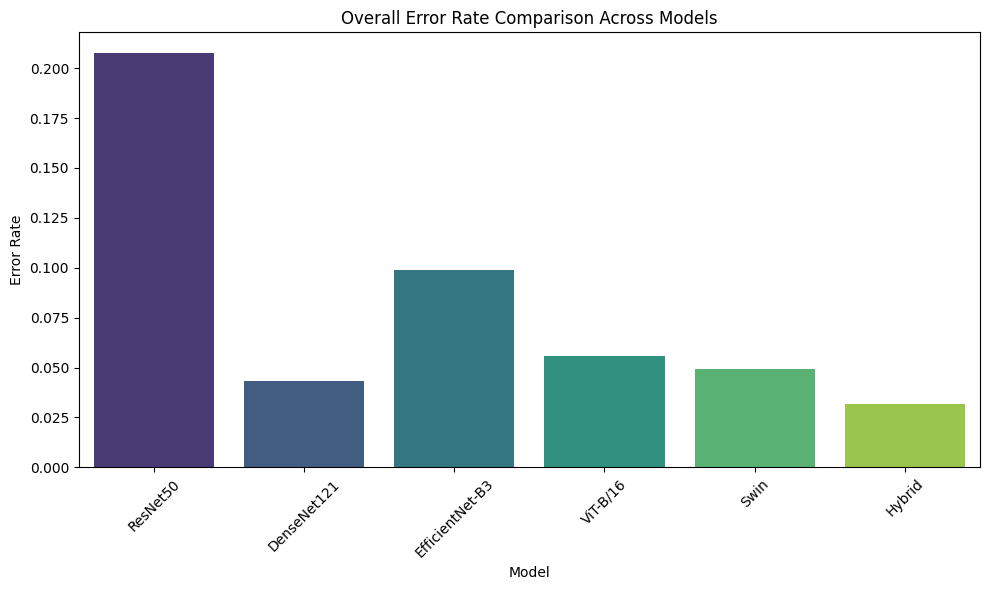

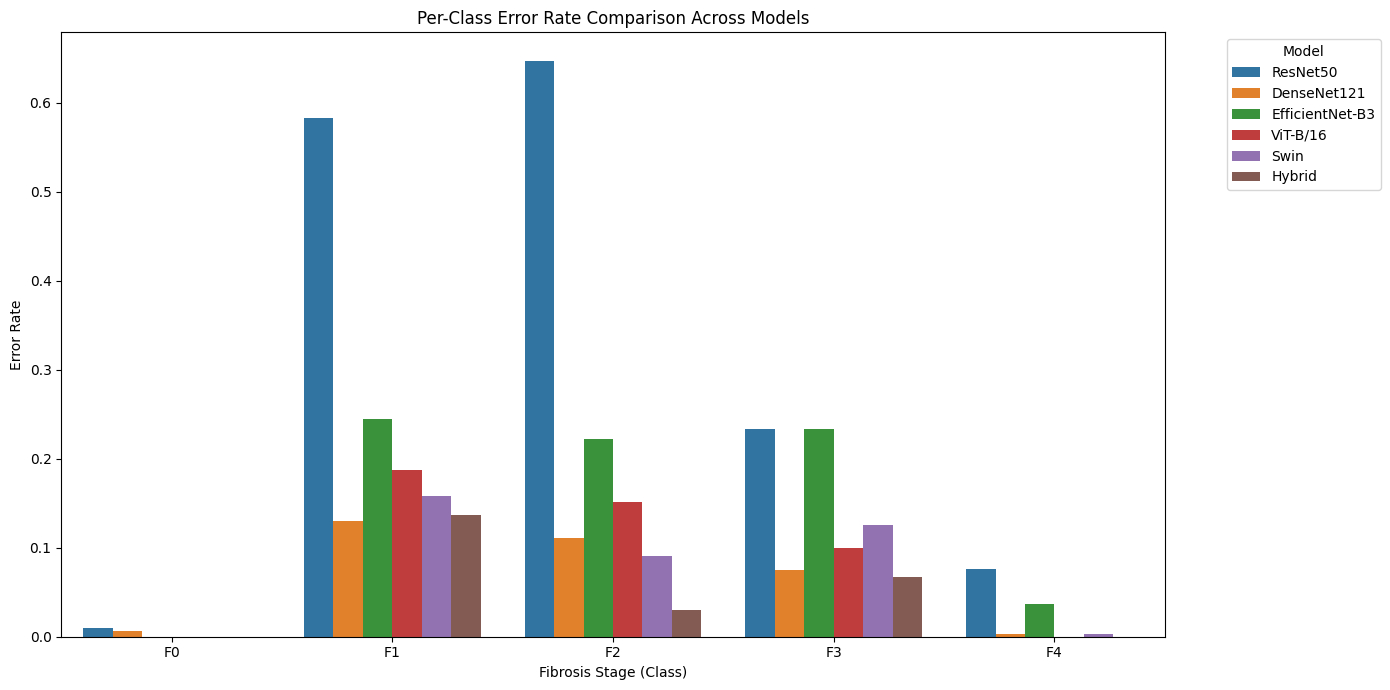

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'overall_error_summary_df' in locals() and not overall_error_summary_df.empty:
    # --- Graph 1: Overall Error Rate Comparison ---
    fig, ax = plt.subplots(figsize=(10, 6))
    overall_error_summary_df['Error_Rate'] = overall_error_summary_df['Error_Rate'].astype(float)
    sns.barplot(x='Model', y='Error_Rate', data=overall_error_summary_df, ax=ax, palette='viridis')
    ax.set_title('Overall Error Rate Comparison Across Models')
    ax.set_xlabel('Model')
    ax.set_ylabel('Error Rate')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "overall_error_rate.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

if 'per_class_error_analysis_df' in locals() and not per_class_error_analysis_df.empty:
    # --- Graph 2: Per-Class Error Rate Comparison ---
    # Ensure Error_Rate is numeric
    per_class_error_analysis_df['Error_Rate'] = per_class_error_analysis_df['Error_Rate'].astype(float)

    fig, ax = plt.subplots(figsize=(14, 7))
    sns.barplot(x='Class', y='Error_Rate', hue='Model', data=per_class_error_analysis_df, ax=ax, palette='tab10')
    ax.set_title('Per-Class Error Rate Comparison Across Models')
    ax.set_xlabel('Fibrosis Stage (Class)')
    ax.set_ylabel('Error Rate')
    ax.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "per_class_error_rate.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


### 11.5. Misclassified Image Examples




--- Misclassified Images for Model: ResNet50 ---


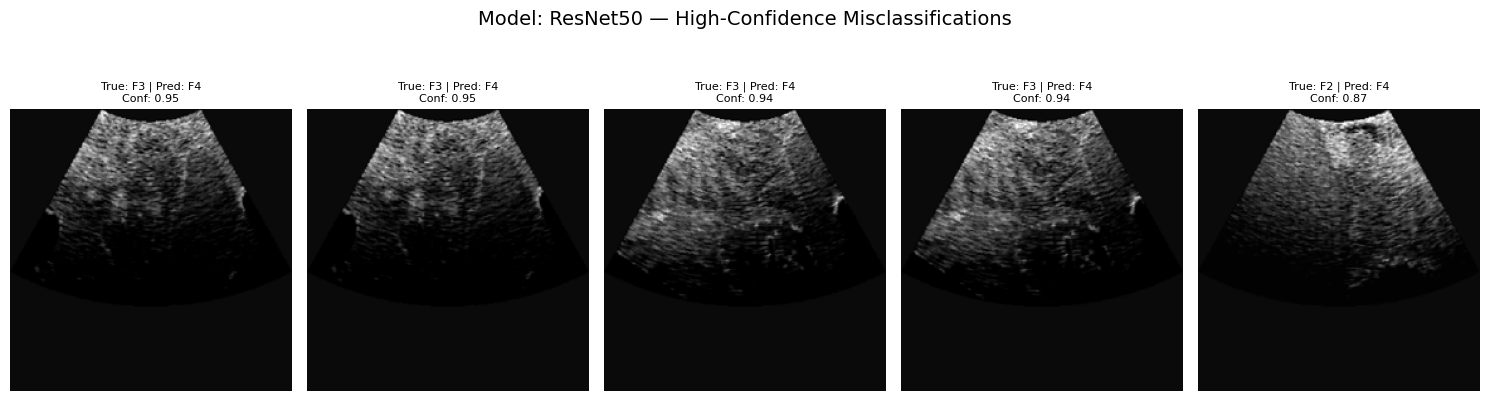


--- Misclassified Images for Model: DenseNet121 ---


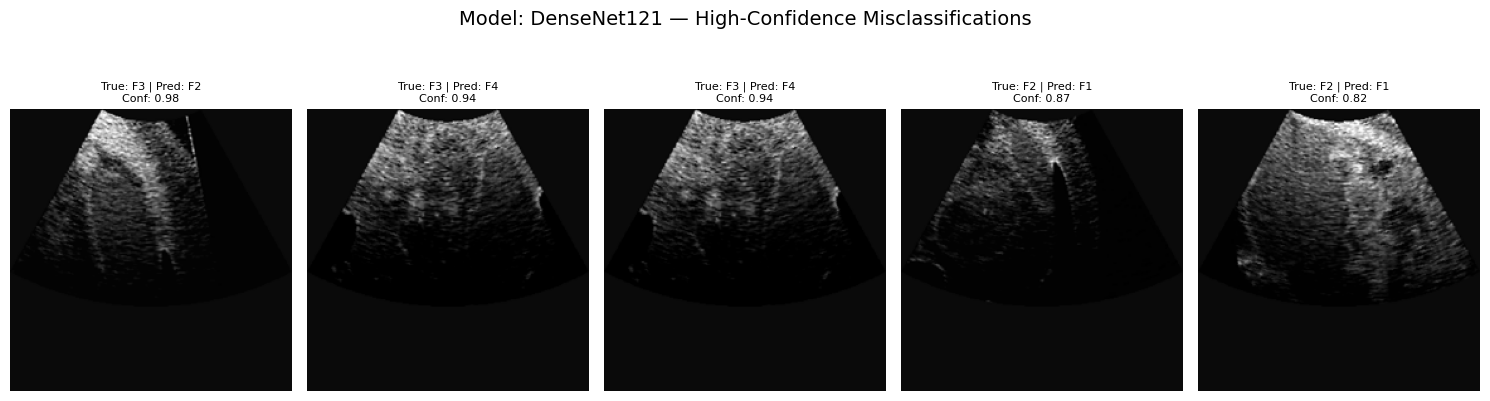


--- Misclassified Images for Model: EfficientNet-B3 ---


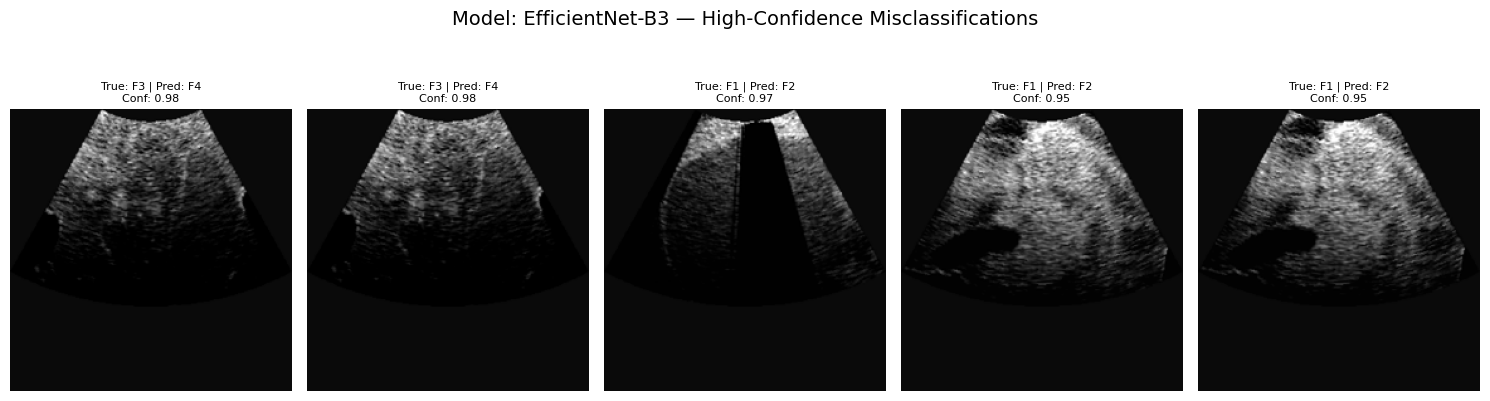


--- Misclassified Images for Model: ViT-B/16 ---


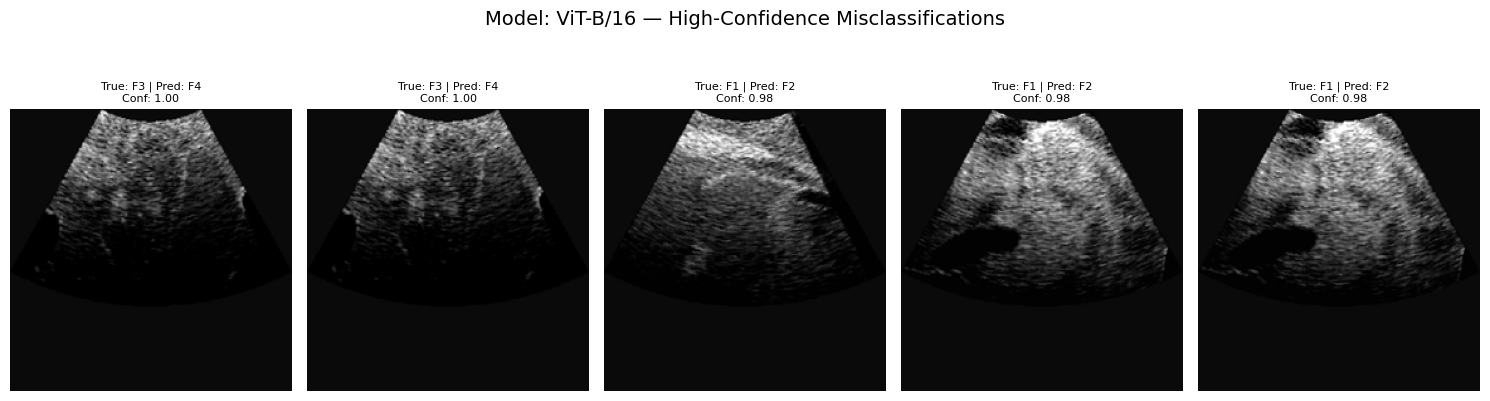


--- Misclassified Images for Model: Swin ---


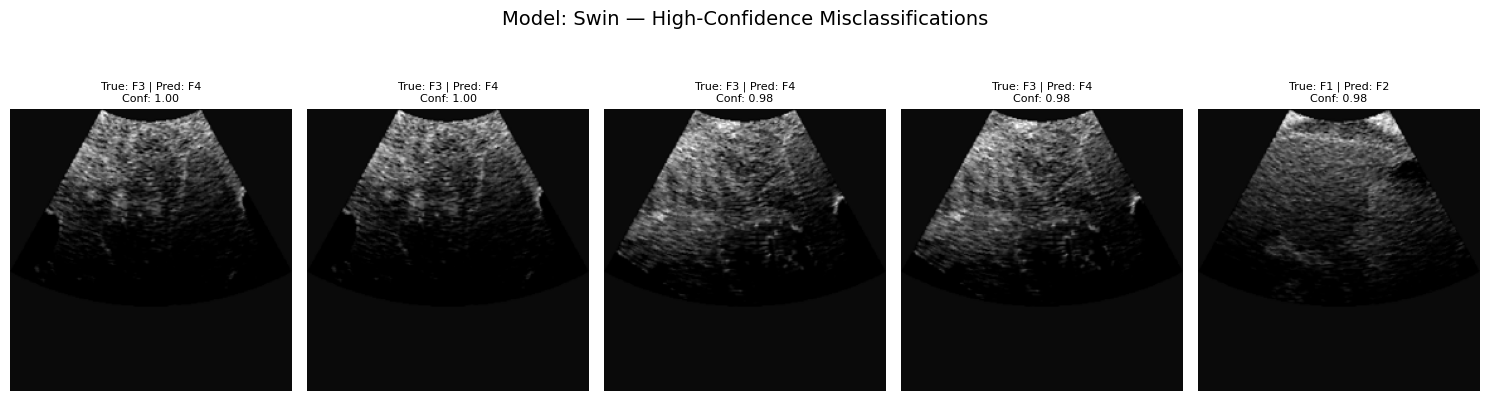


--- Misclassified Images for Model: Hybrid ---


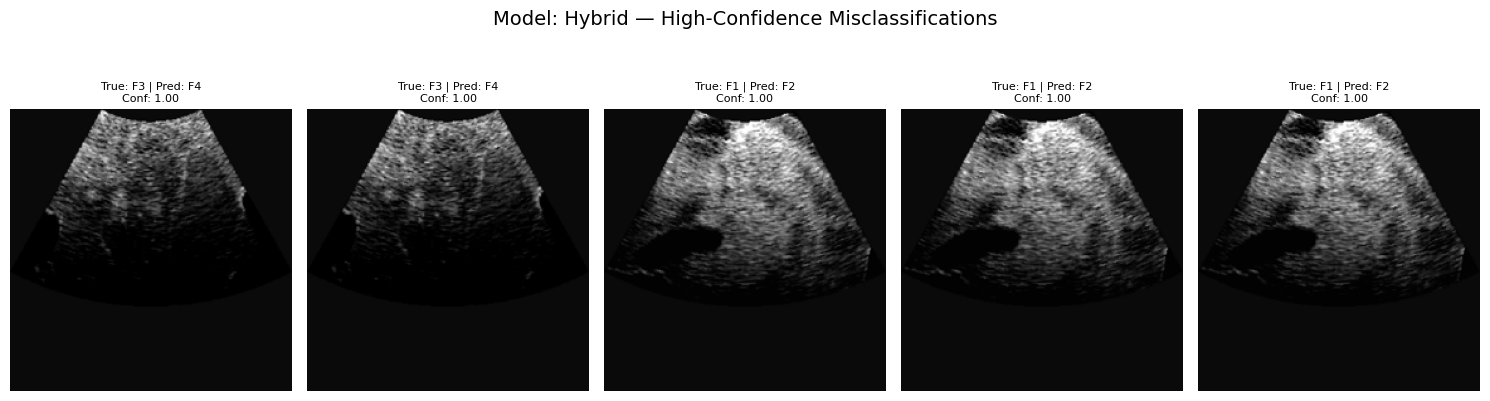

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Assuming eval_tf is available from earlier cells for image loading
# If not, define a simple transform for loading:
# from torchvision import transforms
# eval_tf = transforms.Compose([
#     transforms.Resize((CFG["img_size"], CFG["img_size"])),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
# ])

num_examples_to_display = 5 # Number of misclassified examples per model

if CFG["run_all_models"] and artifacts and CLASSES and 'eval_tf' in locals():
    for model_name, data in artifacts.items():
        print(f"\n--- Misclassified Images for Model: {model_name} ---")
        y_true, y_prob, model_paths = data["pred"]
        y_pred = np.argmax(y_prob, axis=1)

        incorrect_indices = np.where(y_true != y_pred)[0]

        if len(incorrect_indices) == 0:
            print(f"No misclassified images found for {model_name}.")
            continue

        # Get confidence for incorrect predictions (confidence in the *predicted* class)
        incorrect_confidences = y_prob[incorrect_indices, y_pred[incorrect_indices]]

        # Sort by confidence in descending order to highlight high-confidence mistakes
        sorted_incorrect_indices = incorrect_indices[np.argsort(incorrect_confidences)][::-1]

        fig, axes = plt.subplots(1, num_examples_to_display, figsize=(3 * num_examples_to_display, 4))
        fig.suptitle(f"Model: {model_name} — High-Confidence Misclassifications", fontsize=14, y=1.05)

        for i, idx in enumerate(sorted_incorrect_indices[:num_examples_to_display]):
            ax = axes[i]
            img_path = model_paths[idx]
            true_label = CLASSES[y_true[idx]]
            predicted_label = CLASSES[y_pred[idx]]
            confidence = y_prob[idx, y_pred[idx]]

            try:
                pil_img = Image.open(img_path).convert("RGB")
                # Resize for consistent display
                display_img = pil_img.resize((CFG["img_size"], CFG["img_size"]))
                ax.imshow(display_img)
                ax.set_title(f"True: {true_label} | Pred: {predicted_label}\nConf: {confidence:.2f}", fontsize=8)
                ax.axis("off")
            except Exception as e:
                ax.text(0.5, 0.5, f"Error loading\n{os.path.basename(img_path)}\n{e}", ha='center', va='center', fontsize=8)
                ax.axis("off")
                print(f"Error loading image {img_path}: {e}")

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.savefig(PROJECT_ROOT / f"{model_name.replace('/','_')}_misclassified_examples.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)
else:
    print("Misclassified image examples require CFG['run_all_models']=True, trained models, CLASSES, and 'eval_tf'.")


### 11.6. Best Model Detailed Error Analysis




--- Detailed Error Analysis for Best Model: Hybrid ---

Overall Error Summary (Best Model):


,Model,Total_Test_Images,Correct,Incorrect,Error_Rate
5,Hybrid,949,919,30,0.0316



Per-Class Error Analysis (Best Model):


,Model,Class,Total_Samples,Correct_Predictions,Incorrect_Predictions,Error_Rate,Recall
25,Hybrid,F0,316,316,0,0.0000,1.0000
26,Hybrid,F1,139,120,19,0.1367,0.8633
27,Hybrid,F2,99,96,3,0.0303,0.9697
28,Hybrid,F3,120,112,8,0.0667,0.9333
29,Hybrid,F4,275,275,0,0.0000,1.0000



Most Common Confusion Patterns (Best Model):


,Model,Confusion_Pattern,Frequency
47,Hybrid,F1 -> F2,14
48,Hybrid,F1 -> F3,5
49,Hybrid,F3 -> F2,5
50,Hybrid,F2 -> F4,2
51,Hybrid,F3 -> F4,2
52,Hybrid,F2 -> F1,1
53,Hybrid,F3 -> F1,1



Adjacent-Stage Confusion Summary (Best Model):


,Model,Adjacent_Confusion,Frequency
17,Hybrid,F1 <-> F2,15
18,Hybrid,F2 <-> F3,5
19,Hybrid,F3 <-> F4,2



--- Misclassified Images for Best Model: Hybrid ---


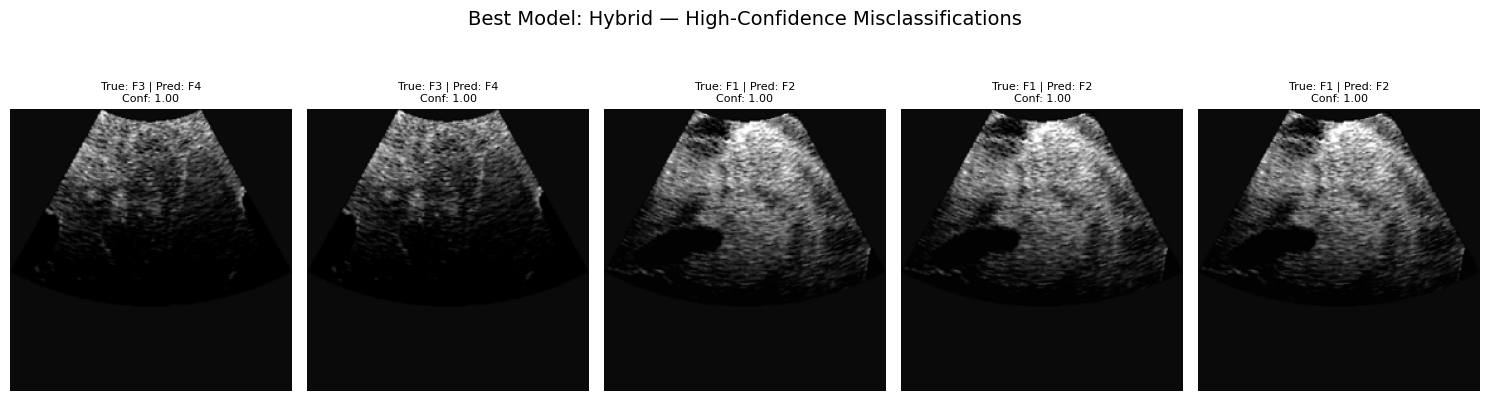

In [ ]:
if 'best_primary' in locals() and best_primary and 'thesis_table' in locals() and not thesis_table.empty:
    print(f"\n--- Detailed Error Analysis for Best Model: {best_primary} ---")

    # 1. Overall Error Rate for Best Model
    if 'overall_error_summary_df' in locals():
        best_model_overall_error = overall_error_summary_df[overall_error_summary_df['Model'] == best_primary]
        print("\nOverall Error Summary (Best Model):")
        display(best_model_overall_error)

    # 2. Per-Class Error Rate for Best Model
    if 'per_class_error_analysis_df' in locals():
        best_model_per_class_error = per_class_error_analysis_df[per_class_error_analysis_df['Model'] == best_primary]
        print("\nPer-Class Error Analysis (Best Model):")
        display(best_model_per_class_error)

    # 3. Most Common Confusions for Best Model
    if 'most_common_confusions_df' in locals():
        best_model_confusions = most_common_confusions_df[most_common_confusions_df['Model'] == best_primary]
        print("\nMost Common Confusion Patterns (Best Model):")
        display(best_model_confusions)

    # 4. Adjacent-Stage Confusions for Best Model
    if 'adjacent_stage_confusions_df' in locals():
        best_model_adjacent_confusions = adjacent_stage_confusions_df[adjacent_stage_confusions_df['Model'] == best_primary]
        print("\nAdjacent-Stage Confusion Summary (Best Model):")
        display(best_model_adjacent_confusions)

    # 5. Misclassified Image Examples for Best Model (re-run the display part)
    print(f"\n--- Misclassified Images for Best Model: {best_primary} ---")
    num_examples_to_display = 5 # Number of misclassified examples per model

    if best_primary in artifacts and 'eval_tf' in locals():
        data = artifacts[best_primary]
        y_true, y_prob, model_paths = data["pred"]
        y_pred = np.argmax(y_prob, axis=1)

        incorrect_indices = np.where(y_true != y_pred)[0]

        if len(incorrect_indices) > 0:
            incorrect_confidences = y_prob[incorrect_indices, y_pred[incorrect_indices]]
            sorted_incorrect_indices = incorrect_indices[np.argsort(incorrect_confidences)][::-1]

            fig, axes = plt.subplots(1, num_examples_to_display, figsize=(3 * num_examples_to_display, 4))
            fig.suptitle(f"Best Model: {best_primary} — High-Confidence Misclassifications", fontsize=14, y=1.05)

            for i, idx in enumerate(sorted_incorrect_indices[:num_examples_to_display]):
                ax = axes[i]
                img_path = model_paths[idx]
                true_label = CLASSES[y_true[idx]]
                predicted_label = CLASSES[y_pred[idx]]
                confidence = y_prob[idx, y_pred[idx]]

                try:
                    pil_img = Image.open(img_path).convert("RGB")
                    display_img = pil_img.resize((CFG["img_size"], CFG["img_size"]))
                    ax.imshow(display_img)
                    ax.set_title(f"True: {true_label} | Pred: {predicted_label}\nConf: {confidence:.2f}", fontsize=8)
                    ax.axis("off")
                except Exception as e:
                    ax.text(0.5, 0.5, f"Error loading\n{os.path.basename(img_path)}\n{e}", ha='center', va='center', fontsize=8)
                    ax.axis("off")
                    print(f"Error loading image {img_path}: {e}")

            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            plt.savefig(PROJECT_ROOT / f"{best_primary.replace('/','_')}_best_model_misclassified_examples.png", dpi=300, bbox_inches="tight")
            plt.show()
            plt.close(fig)
        else:
            print(f"No misclassified images found for best model {best_primary}.")
    else:
        print(f"Cannot display misclassified images for best model {best_primary}. Artifacts or eval_tf not available.")
else:
    print("Detailed best model error analysis requires 'best_primary' and 'thesis_table'.")


### 11.7. Saving

All generated error analysis tables and plots are saved to the project root directory.

In [ ]:
if CFG["run_full_ablation"]:
    # Compact ablation implementation using representative architectures.
    ablation_plan=[
        ("E1","ResNet50","ce",False),
        ("E2","ResNet50","ce",True),
        ("E3","ResNet50","class_weights",True),
        ("E4","Swin","class_weights",True),
        ("E5","Hybrid","class_weights",True),
        ("E6","Hybrid",BEST_STRATEGY,True),
    ]
    ab_rows=[]
    for exp,arch,strategy,use_aug in ablation_plan:
        print("\n====",exp,arch,strategy,"aug=",use_aug)
        train_tf,eval_tf=make_transforms(CFG["img_size"])
        if not use_aug:
            train_tf=eval_tf
        sampler=make_weighted_sampler(train_df) if strategy=="weighted_sampler" else None
        tr=make_loader(train_df,train_tf,CFG["batch_size"],shuffle=True,sampler=sampler,workers=CFG["workers"])
        va=make_loader(val_df,eval_tf,CFG["batch_size"],shuffle=False,workers=CFG["workers"])
        te=make_loader(test_df,eval_tf,CFG["batch_size"],shuffle=False,workers=CFG["workers"])
        m=build_model(arch,pretrained=CFG["pretrained"]).to(DEVICE)
        m,_=train_one(m,tr,va,strategy,train_df,DEVICE,epochs=max(3,CFG["imbalance_epochs"]),lr=CFG["lr"],patience=2)
        y,p,_=predict(m,te,DEVICE)
        met,_,_=classification_metrics(y,p)
        ab_rows.append({"Experiment":exp,"Architecture":arch,"Strategy":strategy,"Augmentation":use_aug,**met})
        del m,tr,va,te
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    ablation_df=pd.DataFrame(ab_rows)
    display(ablation_df)
    ablation_df.to_csv(PROJECT_ROOT/"ablation_results.csv",index=False)
else:
    print("Full ablation disabled. Set CFG['run_full_ablation']=True to run it.")


Full ablation disabled. Set CFG['run_full_ablation']=True to run it.


**12. Explainability**


--- Grad-CAM++ Analysis for Model: ResNet50 ---
  Class F0: Example 'k58.jpg' | True: F0 | Pred: F0 (Conf: 1.00)
  Class F1: Example 'c41.jpg' | True: F1 | Pred: F1 (Conf: 0.95)
  Class F2: Example 'i5303.jpg' | True: F2 | Pred: F2 (Conf: 0.46)
  Class F3: Example 't9994.jpg' | True: F3 | Pred: F3 (Conf: 0.57)
  Class F4: Example 'L3956.jpg' | True: F4 | Pred: F4 (Conf: 1.00)


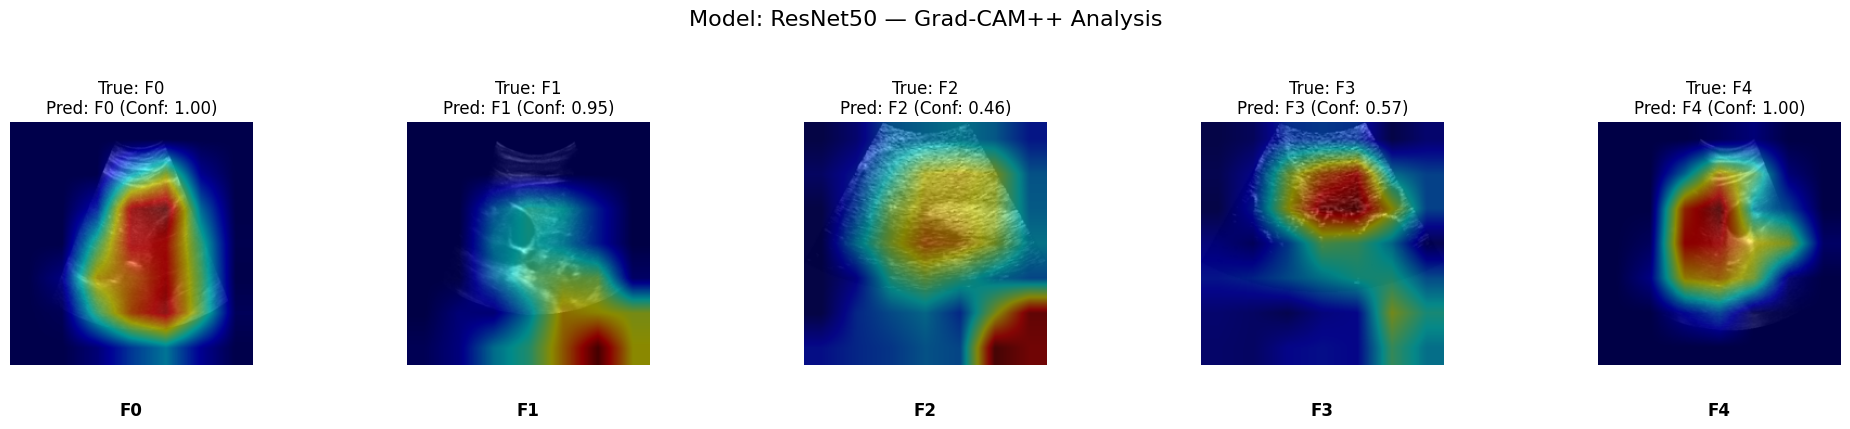


--- Grad-CAM++ Analysis for Model: DenseNet121 ---
  Class F0: Example 'a7496.jpg' | True: F0 | Pred: F0 (Conf: 1.00)
  Class F1: Example 'c22.jpg' | True: F1 | Pred: F1 (Conf: 1.00)
  Class F2: Example 'i5303.jpg' | True: F2 | Pred: F2 (Conf: 1.00)
  Class F3: Example 'K4064.jpg' | True: F3 | Pred: F3 (Conf: 1.00)
  Class F4: Example 'Q3956.jpg' | True: F4 | Pred: F4 (Conf: 1.00)


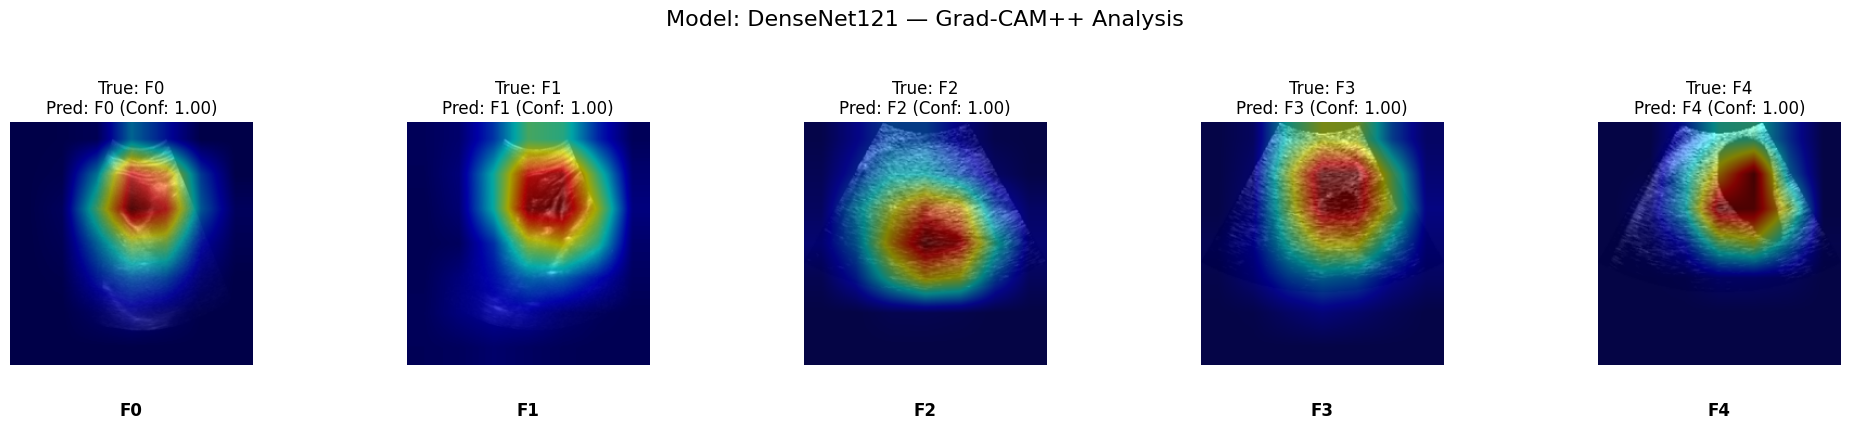


--- Grad-CAM++ Analysis for Model: EfficientNet-B3 ---
  Class F0: Example 'a110.jpg' | True: F0 | Pred: F0 (Conf: 1.00)
  Class F1: Example 'C101.jpg' | True: F1 | Pred: F1 (Conf: 1.00)
  Class F2: Example 'I6252.jpg' | True: F2 | Pred: F2 (Conf: 1.00)
  Class F3: Example 'o6949.jpg' | True: F3 | Pred: F3 (Conf: 1.00)
  Class F4: Example 'Z6406.jpg' | True: F4 | Pred: F4 (Conf: 1.00)


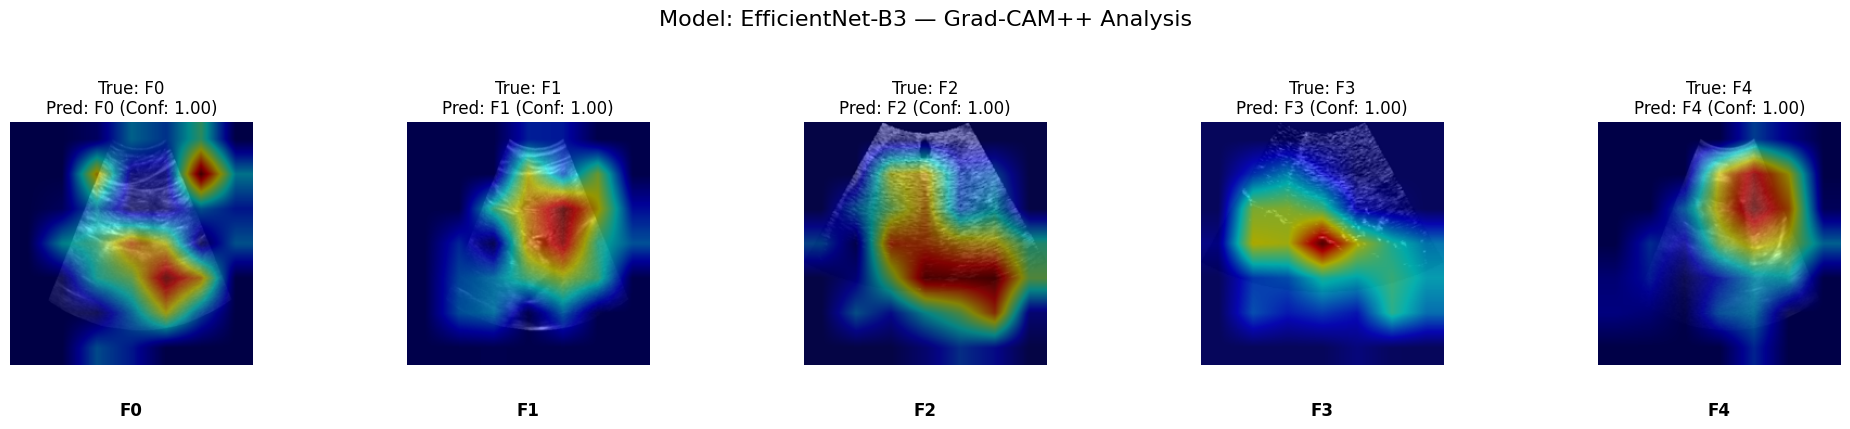


--- Grad-CAM++ Analysis for Model: ViT-B/16 ---
  Class F0: Example 'a4083.jpg' | True: F0 | Pred: F0 (Conf: 1.00)
  Class F1: Example 'b15.jpg' | True: F1 | Pred: F1 (Conf: 1.00)
  Class F2: Example 'X910.jpg' | True: F2 | Pred: F2 (Conf: 1.00)
  Class F3: Example 'ct10-3.png' | True: F3 | Pred: F3 (Conf: 1.00)
  Class F4: Example 'G4841.jpg' | True: F4 | Pred: F4 (Conf: 1.00)


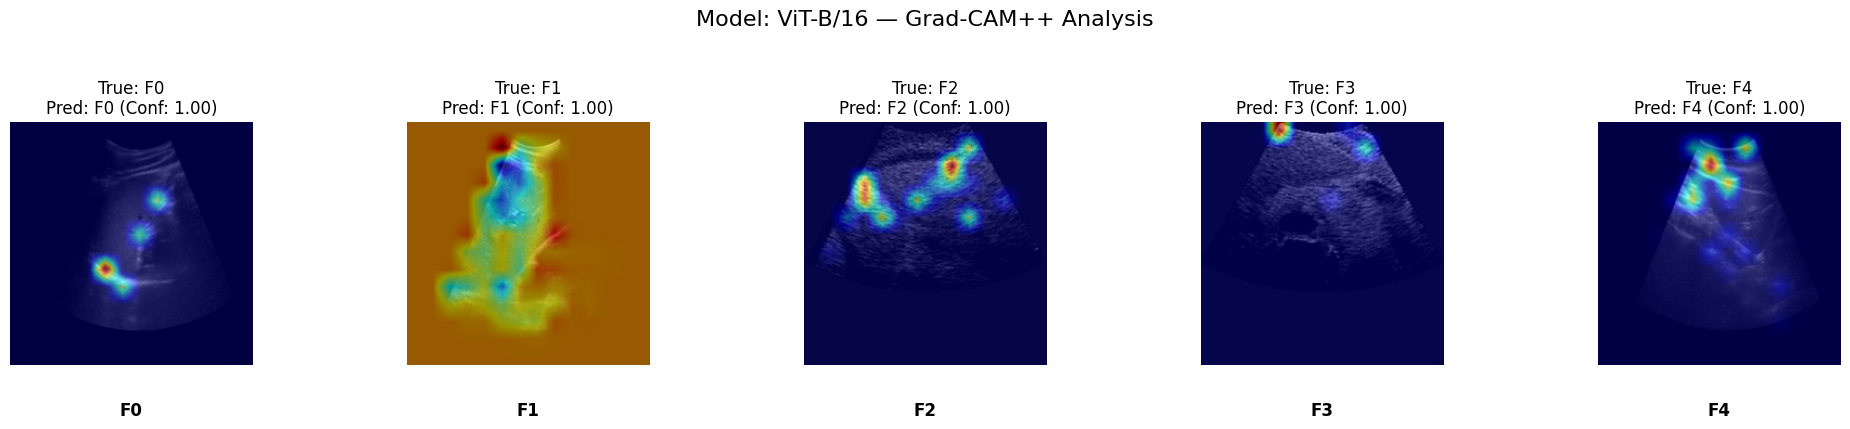


--- Grad-CAM++ Analysis for Model: Swin ---
  Class F0: Example 'k58.jpg' | True: F0 | Pred: F0 (Conf: 1.00)
  Class F1: Example 'M6894.jpg' | True: F1 | Pred: F1 (Conf: 1.00)
  Class F2: Example 'l3108.jpg' | True: F2 | Pred: F2 (Conf: 1.00)
  Class F3: Example 'ct10-70.png' | True: F3 | Pred: F3 (Conf: 1.00)
  Class F4: Example 'g12.jpg' | True: F4 | Pred: F4 (Conf: 1.00)


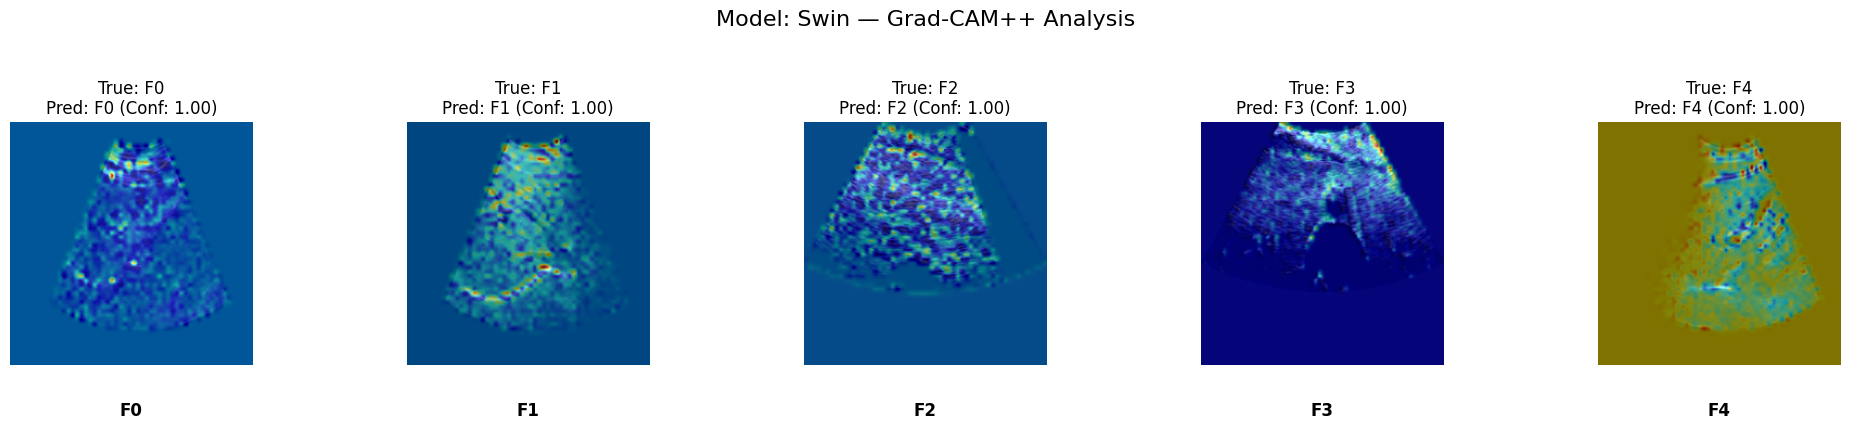


--- Grad-CAM++ Analysis for Model: Hybrid ---
  Class F0: Example 'a2340.jpg' | True: F0 | Pred: F0 (Conf: 1.00)
  Class F1: Example 'c864.jpg' | True: F1 | Pred: F1 (Conf: 1.00)
  Class F2: Example 'I6252.jpg' | True: F2 | Pred: F2 (Conf: 1.00)
  Class F3: Example 'ct10-11.png' | True: F3 | Pred: F3 (Conf: 1.00)
  Class F4: Example 'J5840.jpg' | True: F4 | Pred: F4 (Conf: 1.00)


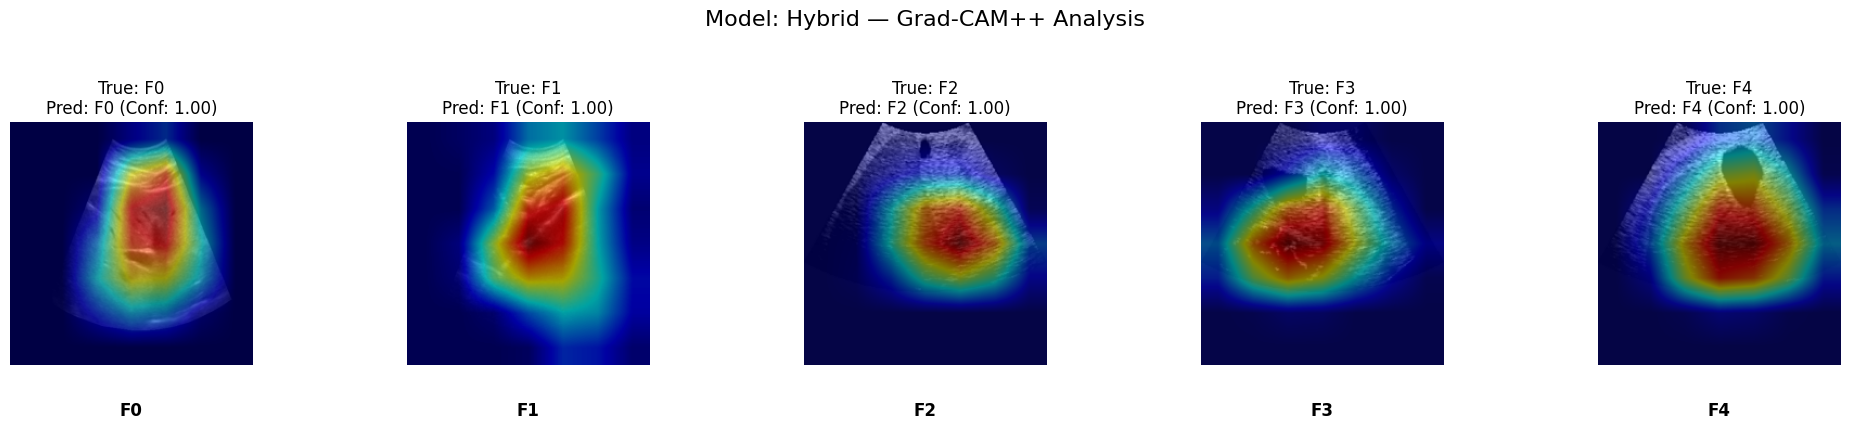

In [ ]:
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pytorch_grad_cam import GradCAMPlusPlus # Using GradCAMPlusPlus as requested
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import os # For os.path.basename

# Clear any previous figures that might be open
plt.close('all')

if CFG["run_all_models"]:
    # Loop through each model in the artifacts for explainability analysis
    for name, a in artifacts.items():
        model = a["model"].eval() # Get the trained model and set to evaluation mode

        # Determine target layers for Grad-CAM++ compatibility
        target_layers = None
        if name == "Hybrid":
            # For the Hybrid model, target the EfficientNet part's final convolutional block
            # Assuming 'conv_head' is the suitable final convolutional layer in the EfficientNet branch
            if hasattr(model, 'eff') and hasattr(model.eff, 'conv_head') and isinstance(model.eff.conv_head, nn.Module):
                # EfficientNet conv_head typically contains a Conv2d layer
                target_layers = [model.eff.conv_head]
            else:
                # Fallback to finding the last Conv2d within the EfficientNet part of Hybrid
                eff_conv_layers = [m for m in model.eff.modules() if isinstance(m, nn.Conv2d)]
                if eff_conv_layers:
                    target_layers = [eff_conv_layers[-1]]
        elif name in ["ResNet50", "DenseNet121", "EfficientNet-B3"]:
            # For standard CNNs, identify the last convolutional layer.
            # This is a common practice for Grad-CAM to highlight high-level features.
            conv_layers = [m for m in model.modules() if isinstance(m, nn.Conv2d)]
            if conv_layers:
                target_layers = [conv_layers[-1]]
        elif name == "ViT-B/16":
            # For ViT-B/16, target the convolutional projection layer in the patch embedding.
            # This layer processes the input image into a sequence of patches, which can be reshaped to 2D activations.
            if hasattr(model, 'patch_embed') and hasattr(model.patch_embed, 'proj') and isinstance(model.patch_embed.proj, nn.Conv2d):
                target_layers = [model.patch_embed.proj]
            else:
                print(f"  Warning: Specific ViT patch_embed.proj not found for {name}. Grad-CAM might fail or produce suboptimal results.")
        elif name == "Swin":
            # For Swin Transformer, target the convolutional projection layer in the patch embedding.
            # This layer transforms the input image into patch embeddings.
            if hasattr(model, 'patch_embed') and hasattr(model.patch_embed, 'proj') and isinstance(model.patch_embed.proj, nn.Conv2d):
                target_layers = [model.patch_embed.proj]
            else:
                print(f"  Warning: Specific Swin patch_embed.proj not found for {name}. Grad-CAM might fail or produce suboptimal results.")

        if target_layers:
            print(f"\n--- Grad-CAM++ Analysis for Model: {name} ---")

            # Prepare a single figure to display all five stages side-by-side
            fig, axes = plt.subplots(1, 5, figsize=(20, 4)) # Single row, 5 columns
            fig.suptitle(f"Model: {name} — Grad-CAM++ Analysis", fontsize=16, y=1.05) # Main title

            model_y, model_p, model_paths = a["pred"] # Get true labels, probabilities, and image paths from test set

            # Select a representative example for each fibrosis class (F0-F4)
            examples_for_classes = {}
            for target_class_idx, class_name in enumerate(CLASSES):
                # Filter for images that truly belong to the current class in the test set
                class_true_indices = np.where(model_y == target_class_idx)[0]

                selected_idx = None

                # Prioritize correctly classified examples with high prediction confidence
                if len(class_true_indices) > 0:
                    correctly_classified_indices_for_this_class = [
                        idx for idx in class_true_indices
                        if model_p[idx].argmax() == target_class_idx
                    ]

                    if correctly_classified_indices_for_this_class:
                        # Pick the example with the highest confidence for its (correct) predicted class
                        confidences = model_p[correctly_classified_indices_for_this_class, target_class_idx]
                        best_correct_idx_in_subset = correctly_classified_indices_for_this_class[np.argmax(confidences)]
                        selected_idx = best_correct_idx_in_subset
                    else:
                        # If no correctly classified examples, try to find an incorrectly classified one for the class
                        incorrectly_classified_indices_for_this_class = [
                            idx for idx in class_true_indices
                            if model_p[idx].argmax() != target_class_idx
                        ]
                        if incorrectly_classified_indices_for_this_class:
                            # Pick the one with highest confidence for its *predicted* class (even if incorrect)
                            confidences = model_p[incorrectly_classified_indices_for_this_class, model_p[incorrectly_classified_indices_for_this_class].argmax(axis=1)]
                            best_incorrect_idx_in_subset = incorrectly_classified_indices_for_this_class[np.argmax(confidences)]
                            selected_idx = best_incorrect_idx_in_subset
                        else:
                            # Fallback: if no correctly or incorrectly classified examples found for this true class, take the first available
                            selected_idx = class_true_indices[0] # Should not happen if test set is diverse

                if selected_idx is not None:
                    # Get prediction details for the selected example
                    pred_label_idx = model_p[selected_idx].argmax()
                    pred_confidence = model_p[selected_idx, pred_label_idx]
                    examples_for_classes[class_name] = {
                        "path": model_paths[selected_idx],
                        "true_label": CLASSES[model_y[selected_idx]],
                        "predicted_label": CLASSES[pred_label_idx],
                        "confidence": pred_confidence,
                        "pred_idx": pred_label_idx # Store the index of the predicted class for Grad-CAM++ target
                    }
                else:
                    print(f"  Warning: No suitable example found in test set for true class {class_name} for model {name}.")


            # Generate and plot Grad-CAM++ for each selected example
            for i, class_name in enumerate(CLASSES):
                ax = axes[i]
                if class_name in examples_for_classes:
                    ex = examples_for_classes[class_name]
                    print(f"  Class {class_name}: Example '{os.path.basename(ex['path'])}' | True: {ex['true_label']} | Pred: {ex['predicted_label']} (Conf: {ex['confidence']:.2f})")

                    pil_img = Image.open(ex['path']).convert("RGB")
                    # Apply evaluation transforms to get the input tensor for the model
                    input_tensor = eval_tf(pil_img).unsqueeze(0).to(DEVICE)

                    # Initialize Grad-CAM++
                    cam_extractor = GradCAMPlusPlus(model=model, target_layers=target_layers)

                    # Target the *predicted* class for generating the heatmap, as per request
                    targets = [ClassifierOutputTarget(ex['pred_idx'])]

                    # Generate the Grad-CAM++ heatmap
                    grayscale_cam = cam_extractor(input_tensor=input_tensor, targets=targets)[0, :]

                    # Resize the original PIL image to the target image size for proper overlay
                    rgb_img_for_overlay = np.array(pil_img.resize((CFG["img_size"], CFG["img_size"]))).astype(np.float32) / 255.0

                    # Overlay the heatmap on the original image
                    visualization = show_cam_on_image(rgb_img_for_overlay, grayscale_cam, use_rgb=True)

                    ax.imshow(visualization)
                    ax.axis("off") # Hide axes ticks and labels
                    ax.set_title(f"True: {ex['true_label']}\nPred: {ex['predicted_label']} (Conf: {ex['confidence']:.2f})")
                    ax.text(0.5, -0.15, class_name, ha='center', va='top', transform=ax.transAxes, fontsize=12, fontweight='bold') # F0-F4 label below

                    # Optional: Save individual stage figures if needed
                    individual_filename = PROJECT_ROOT / f"{name.replace('/','_')}_Explainability_{class_name}.jpg"
                    plt.imsave(individual_filename, visualization, dpi=300)
                else:
                    # Display a placeholder if no example was found for a class
                    ax.text(0.5, 0.5, f"No data for {class_name}", ha='center', va='center', transform=ax.transAxes)
                    ax.axis("off")

            plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap

            # Construct filename as requested
            if name == "Hybrid":
                figure_filename = PROJECT_ROOT / f"Hybrid_EfficientNet_GradCAMpp_F0_F4.jpg"
            elif name == "ViT-B/16":
                figure_filename = PROJECT_ROOT / f"ViT_B16_Transformer_Explainability_F0_F4.jpg"
            elif name == "Swin":
                figure_filename = PROJECT_ROOT / f"Swin_Transformer_Explainability_F0_F4.jpg"
            else:
                figure_filename = PROJECT_ROOT / f"{name.replace('/','_')}_GradCAMpp_F0_F4.jpg"

            # Save the combined thesis-ready figure
            plt.savefig(figure_filename, dpi=300, bbox_inches="tight") # High-res JPEG
            plt.show() # Display the figure
            plt.close(fig) # Close the figure to free up memory

            # Clear variables for the current model to manage memory
            del model, cam_extractor, targets, grayscale_cam, rgb_img_for_overlay, visualization, input_tensor
            if torch.cuda.is_available(): torch.cuda.empty_cache() # Clear CUDA cache if available

        else:
            print(f"\n--- Explainability skipped for {name} (architecture not compatible or suitable target layers not found). ---")

else:
    print("Set CFG['run_all_models']=True to run explainability analysis.")